# Clusterização de Clientes para Direcionamento de Vendas

### 📌 Sumário Executivo e Guia de Navergação Rápida
Escolha o foco da sua leitura e clique no link para navegar diretamente até a seção desejada:

- 📊 [1. Entendimento do Negócio](#secao_1) 
— Acabar com a panfletagem digital e focar em ofertas de alta conversão.

- 🔍 [2. Análise Exploratória dos Dados](#secao_2) 
— Registros revelando anomalias de cadastro, colisões de strings e os primeiros padrões ocultos.

- 🛠️ [3. Preparação e Limpeza dos Dados](#secao_3) 
— Engenharia de dados em ação: expurgo de ruídos, imputação por mediana e codificação binária das variáveis.

- 🤖 [4. Modelagem Estatística com Machine Learning](#secao_4) 
— A matemática decide: validando a divisão ideal da base através do Método do Cotovelo e Silhouette Score.

- 🎯 [5. Avaliação de Personas e Perfilamento](#secao_5) 
— Traduzindo algoritmos em pessoas: o mapeamento demográfico e comportamental das 5 novas personas.

- 💵 [6. Business Case e Retorno Financeiro (ROI)](#secao_6) 
— Dinheiro na mesa: a simulação real que reverteu um prejuízo e injetou 65k de lucro líquido na operação.

- 📈 [7. Roadmap de Produção e Implementação](#secao_7) 
— Da teoria à prática: a arquitetura automatizada (Airflow/SQL) para dar total autonomia ao time de marketing.

---

##### 💻 Você está aqui pelo processo técnico e pelas linhas de código?
[Clique aqui para iniciar a jornada pelo código](#secao_1) e acompanhe etapa por etapa a construção da engenharia de atributos, tratamento de anomalias e treinamento estatístico.

##### 🎯 Você está aqui pelo resultado final focado em estratégia e negócios?
[Vá direto para o Business Case e Conclusões Finais](#secao_6) para entender o lucro real em Reais injetado na companhia e o plano de direcionamento de marketing de precisão.

---

<div id='secao_1'></div>

# 1. Entendimento do Negócio

### 1.1 Objetivos

O time de Estratégia Comercial da vertical de **Financiamento de Veículos** solicitou apoio analítico para otimizar suas operações de vendas digitais. 

Atualmente, o parceiro enfrenta dificuldades no gerenciamento e na oferta personalizada de seus produtos financeiros para a base de clientes. Nossa principal tarefa é **identificar perfis de consumo e comportamento de crédito (Machine Learning - Clusterização)** para que a liderança possa basear suas tomadas de decisão em dados estruturados, aumentando a conversão de vendas e mitigando riscos.
    
### 1.2 Premissas

* Construir uma clusterização robusta utilizando o dataset de 10.000 registros reais.
* Documentar as escolhas e o raciocínio analítico etapa por etapa (utilizando comentários e Markdown).
* Manter alto padrão de organization, lógica de programação e boas práticas de manipulação de dados.

<h3>1.3 Critérios de Sucesso</h3>

Identificar e perfilar os grupos de clientes (personas), gerando um mapeamento descritivo e preditivo acompanhado de recomendações estratégicas de produtos e simulação de ganho monetário incremental para cada cluster.



<h1>0. Entendimento dos Dados</h1>

<h4>0.1 Instalação e importação das bibliotecas</h4>

<h5>0.1.1. Descrição dos Pacotes e Documentações Oficiais</h5> 

*   **Pandas** ([Documentação Oficial](https://pandas.pydata.org/docs/)): Estrutura principal de manipulação de dados (`DataFrames`). Permite limpeza rápida, filtros, agrupamentos e tratamento de dados faltantes ou formatos incompatíveis na base de financiamento.
*   **Seaborn** ([Documentação Oficial](https://seaborn.pydata.org/)): Biblioteca de visualização estatística construída sobre o Matplotlib. Essencial para criar gráficos de dispersão, distribuições e mapas de calor elegantes para identificar padrões ocultos nos clientes.
*   **Scikit-Learn** ([Documentação Oficial](https://scikit-learn.org)): O ecossistema padrão para Machine Learning em Python. Contém os algoritmos de pré-processamento, métricas de validação matemática e o modelo K-Means que usaremos para agrupar os clientes.
*   **NumPy** ([Documentação Oficial](https://numpy.org/doc/)): Biblioteca para computação matemática e operações de vetores de alta performance. Dá suporte de infraestrutura para cálculos estatísticos por trás do algoritmo de clusterização.
*   **Matplotlib** ([Documentação Oficial](https://matplotlib.org/stable/index.html)): A fundação gráfica do Python. Utilizada para a customização refinada de eixos, tamanhos de figuras e salvamento dos plots para apresentações executivas.


<h5>
0.1.2 Importação das Bibliotecas;
</h5>

- Bibliotecas para pré-processamento e clusterização

In [1]:
# 0.1.2 Importação das Bibliotecas com Justificativa Técnica

# Manipulação de Estruturas de Dados
import pandas as pd
import numpy as np

# Visualização Gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento: StandardScaler é vital para o K-Means, pois padroniza a escala das variáveis 
# numéricas (Ex: Renda Mensal na casa de milhares vs Nota de Satisfação de 1 a 10), evitando viés de distância.
from sklearn.preprocessing import StandardScaler

# Modelagem Preditiva: KMeans agrupa os dados minimizando a variância interna dos clusters.
from sklearn.cluster import KMeans

# Métricas de Avaliação: silhouette_score mede a qualidade da separação matemática dos grupos criados.
from sklearn.metrics import silhouette_score

# Análise de Agrupamento Hierárquico (Caso queira analisar a estrutura de dendrograma da base)
from scipy.cluster.hierarchy import dendrogram, linkage

# Configurações estéticas padrão para o portfólio
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("Todas as bibliotecas e dependências técnicas foram importadas com sucesso!")


Todas as bibliotecas e dependências técnicas foram importadas com sucesso!


<h5>
0.3 Extração da base dos dados;
</h5>

In [2]:
df = pd.read_excel('base_clientes_banco_auto_nova.xlsx')

<h5>
    0.4 Dicionário dos Dados (Metadados);
</h5> 

<h5>0.4.1 Extração da base dos dados</h5>

Nesta etapa realizamos o carregamento dos dados históricos coletados dos acessos e contratos dos clientes da plataforma de financiamento.

<h3>0.4.2 Dicionário dos Dados (Metadados)</h3> 

A base de dados possui **10.000 registros** distribuídos em **10 colunas** estruturadas da seguinte forma:

* **id_cliente** (Alfanumérico): Identificador exclusivo do cliente na carteira. *Nota de Auditoria: Apresenta valores nulos (Faltantes) devido a falhas de sincronização de sistemas.*
* **idade** (Inteiro): Idade em anos completos. *Nota de Auditoria: Apresenta anomalias sistêmicas (valores negativos e acima de 100 anos) decorrentes de erros de digitação.*
* **genero** (Texto): Gênero registrado do cliente. *Nota de Auditoria: Apresenta inconsistência de escrita (F, M, Feminino, Masculino) que exigirá unificação na etapa de Data Cleansing.*
* **estado_civil** (Texto): Estado civil declarado. *Nota de Auditoria: Apresenta duplicidades de grafia (Solteiro, solteiro, CASADO, Casado) que serão tratadas.*
* **renda_mensal** (Decimal): Renda líquida mensal comprovada ou estimada em R\$ . *Nota de Auditoria: Apresenta valores vazios (NaN) e outliers absurdos oriundos de digitação.*
* **score_credito** (Inteiro): Pontuação de score no birô de crédito (variando de 200 a 1000).
* **produto_automotivo_digital** (Texto): Principal produto ou serviço automotivo ativo do cliente.
* **valor_contrato_compra** (Decimal): Valor monetário total do contrato ativo em R\$ .
* **frequencia_interacao_6m** (Inteiro): Quantidade de acessos/interações nos canais digitais nos últimos 6 meses.
* **satisfacao** (Decimal): Nota dada pelo cliente à experiência geral (CSAT na escala de 1 a 10). *Nota de Auditoria: Contém valores nulos de clientes que optaram por não responder à pesquisa.*



<h3>
    2. Análise Exploratória dos dados;
</h3>   

<h5>
    2.1.1.1 Visualização das primeiras e ultimas linhas da tabela;
</h5> 

In [3]:
df.head()

,id_cliente,idade,genero,estado_civil,renda_mensal,score_credito,produto_automotivo_digital,valor_contrato_compra,frequencia_interacao_6m,satisfacao
0,C_00001,50,M,Divorciado,6157.63,463,Empréstimo com Garantia de Veículo,91335.65,10,7.0
1,C_00002,23,F,Solteiro(a),3952.27,282,Seguro Auto Conectado,2863.28,8,7.0
2,C_00003,31,Masculino,DIVORCIADO,7028.78,716,Empréstimo com Garantia de Veículo,62925.90,8,8.0
3,C_00004,48,F,solteiro,12065.22,470,Seguro Auto Conectado,4010.27,8,8.0
4,C_00005,46,M,Divorciado,13270.07,854,Consórcio Auto Flex,142144.18,4,9.0


In [4]:
df.tail()

,id_cliente,idade,genero,estado_civil,renda_mensal,score_credito,produto_automotivo_digital,valor_contrato_compra,frequencia_interacao_6m,satisfacao
9995,C_09996,22,M,Solteiro(a),4789.82,256,Tag de Pedágio + Conta Cartão,805.82,2,5.0
9996,C_09997,26,M,Solteiro(a),4121.17,204,Tag de Pedágio + Conta Cartão,1020.84,5,7.0
9997,C_09998,19,Feminino,solteiro,4401.62,381,Seguro Auto Conectado,2262.77,9,6.0
9998,C_09999,49,F,Casado(a),9828.82,571,Empréstimo com Garantia de Veículo,47864.60,4,8.0
9999,C_10000,38,Masculino,Solteiro(a),9552.04,617,Empréstimo com Garantia de Veículo,44634.56,7,7.0


**🎯 Por que essa etapa é importante para o negócio?**
A visualização inicial da "cabeça" (`head`) e da "cauda" (`tail`) do dataset serve como um primeiro contato prático com a integridade dos dados reais de financiamento. Ela permite validar se a carga foi feita corretamente e se os registros seguem o padrão esperado pelo banco de dados (ex: IDs sequenciais, valores monetários estruturados em Reais e categorias textuais limpas). 

*   **Insight de Negócio Instantâneo:** Já notamos de imediato a presença de 5 tipos diferentes de produtos digitais (como *Financiamento CDC*, *Tags de Pedágio* e *Consórcio*), o que reforça o desafio comercial de criar grupos de clientes bem definidos para ofertas personalizadas.


<h5>
    2.1.1.2 Visualizando o tamanho total do dataset;
</h5> 

In [5]:
df.shape

(10000, 10)

**🎯 Por que essa etapa é importante para o negócio?**
Saber a volumetria exata do banco de dados dita a relevância estatística do projeto. Um universo de **10.000 clientes ativos** com 10 atributos diferentes oferece uma base estatisticamente sólida e robusta para treinar modelos de Machine Learning estáveis. Modelos criados em bases muito pequenas podem gerar falsas segmentações e prejudicar as campanhas comerciais.

<h5>
    2.1.1.3 Visualizando o nome de cada uma das colunas;
</h5> 

In [6]:
df.columns

Index(['id_cliente', 'idade', 'genero', 'estado_civil', 'renda_mensal',
       'score_credito', 'produto_automotivo_digital', 'valor_contrato_compra',
       'frequencia_interacao_6m', 'satisfacao'],
      dtype='object')

**🎯 Por que essa etapa é importante para o negócio?**
Mapear os nomes das variáveis garante que todas as dimensões essenciais para a regra de negócio de crédito automotivo estejam presentes. Aqui confirmamos que temos variáveis de **perfil demográfico** (idade, gênero, estado civil), **saúde financeira** (renda mensal, score de crédito), **comportamento de compra** (produto, valor do contrato) e **engajamento/lealdade** (frequência de interação e nota de satisfação CSAT).


<h5>
    2.1.1.4 Verificando a indexação das linhas;
</h5> 

In [7]:
df.index

RangeIndex(start=0, stop=10000, step=1)

**🎯 Por que essa etapa é importante para o negócio?**
Garante que a base está estruturada de forma sequencial contínua (do registro 0 ao 10000) e sem saltos de linhas. Essa validação estrutural é fundamental para que, na fase de modelagem, o algoritmo de clusterização consiga amarrar o rótulo do cluster correto de volta a cada cliente individual sem causar desalinhamento de dados.


<h5>
    2.1.1.5 Analise de valores únicos dentro das colunas;
</h5> 

In [8]:
df.nunique()

id_cliente                    9967
idade                           57
genero                           4
estado_civil                     6
renda_mensal                  9823
score_credito                  800
produto_automotivo_digital       5
valor_contrato_compra         9988
frequencia_interacao_6m         21
satisfacao                       7
dtype: int64

**🎯 Por que essa etapa é importante para o negócio?** 

O comando `.nunique()` nos revela a diversidade e a cardinalidade real de cada coluna. Para o time de planejamento e inteligência de mercado, analisar esses números antes do tratamento ajuda a acender alertas críticos sobre a qualidade do banco de dados:

- **id_cliente com 9.967 valores únicos** em uma base de 10.000 linhas acende um alerta imediato de auditoria. Isso indica a presença de registros duplicados ou campos vazios que precisarão de expurgo na etapa de limpeza.
- **genero com 4 valores únicos e estado_civil com 6** provam estatisticamente a existência de inconsistências cadastrais e falta de padronização na digitação do sistema (ex: convivência de grafias como Masculino, M, solteiro e Solteiro).
- **produto_automotivo_digital com exatamente 5 produtos distintos** consolida a nossa oportunidade de desenhar estratégias robustas de cross-selling entre as carteiras.
- **satisfacao limitada a apenas 7 valores únicos** indica que a escala tradicional de 1 a 10 não está totalmente preenchida na base atual, possivelmente devido à ausência de notas extremas ou registros nulos de clientes que optaram por não responder.



<h5>
    2.1.1.7 Analisando o formato de cada coluna;
</h5> 

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id_cliente                  9967 non-null   object 
 1   idade                       10000 non-null  int64  
 2   genero                      10000 non-null  object 
 3   estado_civil                10000 non-null  object 
 4   renda_mensal                9880 non-null   float64
 5   score_credito               10000 non-null  int64  
 6   produto_automotivo_digital  10000 non-null  object 
 7   valor_contrato_compra       10000 non-null  float64
 8   frequencia_interacao_6m     10000 non-null  int64  
 9   satisfacao                  9850 non-null   float64
dtypes: float64(3), int64(3), object(4)
memory usage: 781.4+ KB


**🎯 Por que essa etapa é importante para o negócio?**

Os algoritmos de clusterização (como o K-Means) operam com cálculos matemáticos de distância, exigindo dados estritamente numéricos (inteiros ou decimais). Identificar quais colunas são textuais (object) nos dá o mapa exato das transformações de engenharia de dados (Encoding) que precisaremos fazer nas etapas seguintes.

**📋 Diagnóstico de Auditoria e Qualidade dos Dados:**

O resultado do comando revela com precisão cirúrgica a existência de dados faltantes na nova base de 10.000 registros, mapeando os pontos que exigirão tratamento na fase de Data Cleansing:

- **id_cliente apresenta apenas 9.967 linhas preenchidas**, confirmando que temos 33 registros sem identificação única de cliente na base.
- **renda_mensal apresenta 9.880 linhas preenchidas**, indicando 120 clientes com omissão de dados de receita financeira.
- **satisfacao apresenta 9.850 linhas preenchidas**, apontando que 150 clientes não responderam à pesquisa de CSAT. Nota-se que o tipo do dado foi convertido automaticamente para decimal (float64) pelo Pandas para conseguir suportar a presença dos valores nulos (NaN).

*Nota de Auditoria de Dados:* Como observado na análise estrutural, caso existissem colunas puras de data no estilo temporal, elas seriam descartadas neste primeiro momento por não agregarem valor preditivo direto à distância geométrica dos clusters, otimizando o custo computacional do projeto.


<h5>
    2.1.1.8 Identificando valores missing;
</h5> 

In [10]:
df.isnull().sum()

id_cliente                     33
idade                           0
genero                          0
estado_civil                    0
renda_mensal                  120
score_credito                   0
produto_automotivo_digital      0
valor_contrato_compra           0
frequencia_interacao_6m         0
satisfacao                    150
dtype: int64

**🎯 Por que essa etapa é importante para o negócio?**

Dados faltantes (missing data) são um dos maiores gargalos na ciência de dados corporativa, pois geram furos em relatórios gerenciais e quebram os modelos preditivos baseados em cálculo de distância geométrica. Identificar a volumetria exata de dados ausentes nos dá o mapa de risco para desenhar as estratégias de limpeza.

**📋 Diagnóstico Crítico dos Dados Ausentes Encontrados:**

Diferente de um cenário idealizado, a nossa auditoria identificou lacunas reais de preenchimento que exigirão ações específicas na fase de Preparação dos Dados:

- **id_cliente apresenta 33 valores nulos:** Indica falhas de gravação de registros novos no sistema. Como não podemos associar essas linhas a clientes reais e o volume é insignificante (0,33 por cento da base), a estratégia de negócio será o expurgo direto dessas linhas.
- **renda_mensal apresenta 120 valores nulos:** Clientes que omitiram a comprovação de renda no cadastro digital. Para não descartar essa volumetria preciosa de potenciais compradores, aplicaremos a imputação estatística pela mediana do grupo.
- **satisfacao apresenta 150 valores nulos:** Clientes que optaram por não responder à pesquisa de CSAT pós-venda. Também trataremos essa coluna aplicando a imputação por mediana para estabilizar o aprendizado do algoritmo.



<h5>
    2.1.1.9 Visualizar linhas duplicadas;
</h5> 

In [11]:
df.duplicated().sum()

0

**🎯 Por que essa etapa é importante para o negócio?**
Registros duplicados inflam artificialmente a base de dados, gerando distorções estatísticas nas médias de renda, desvios padrões de score e, consequentemente, desenhando perfis de clusters distorcidos da realidade do mercado. A confirmação de **0 linhas duplicadas** assegura que cada registro representa um cliente único e legítimo na carteira de financiamento de carros.


<h5>
    2.2 Analise descritiva;
</h5> 

📈 Estatísticas Descritivas das Variáveis Numéricas:


,count,mean,std,min,25%,50%,75%,max
idade,10000.0,39.470200,1.392348e+01,-9.00,28.0000,40.000,49.0000,145.00
renda_mensal,9880.0,71427.945642,2.365080e+06,-2500.00,4604.2675,7347.520,9778.5675,88888888.00
score_credito,10000.0,603.094500,1.971375e+02,200.00,469.0000,601.000,751.0000,999.00
valor_contrato_compra,10000.0,58001.630875,5.101611e+04,501.18,2963.1575,58053.085,88994.5075,179970.59
frequencia_interacao_6m,10000.0,8.032800,2.633328e+00,1.00,6.0000,8.000,10.0000,21.00
satisfacao,9850.0,7.479188,1.340961e+00,4.00,7.0000,8.000,8.0000,10.00


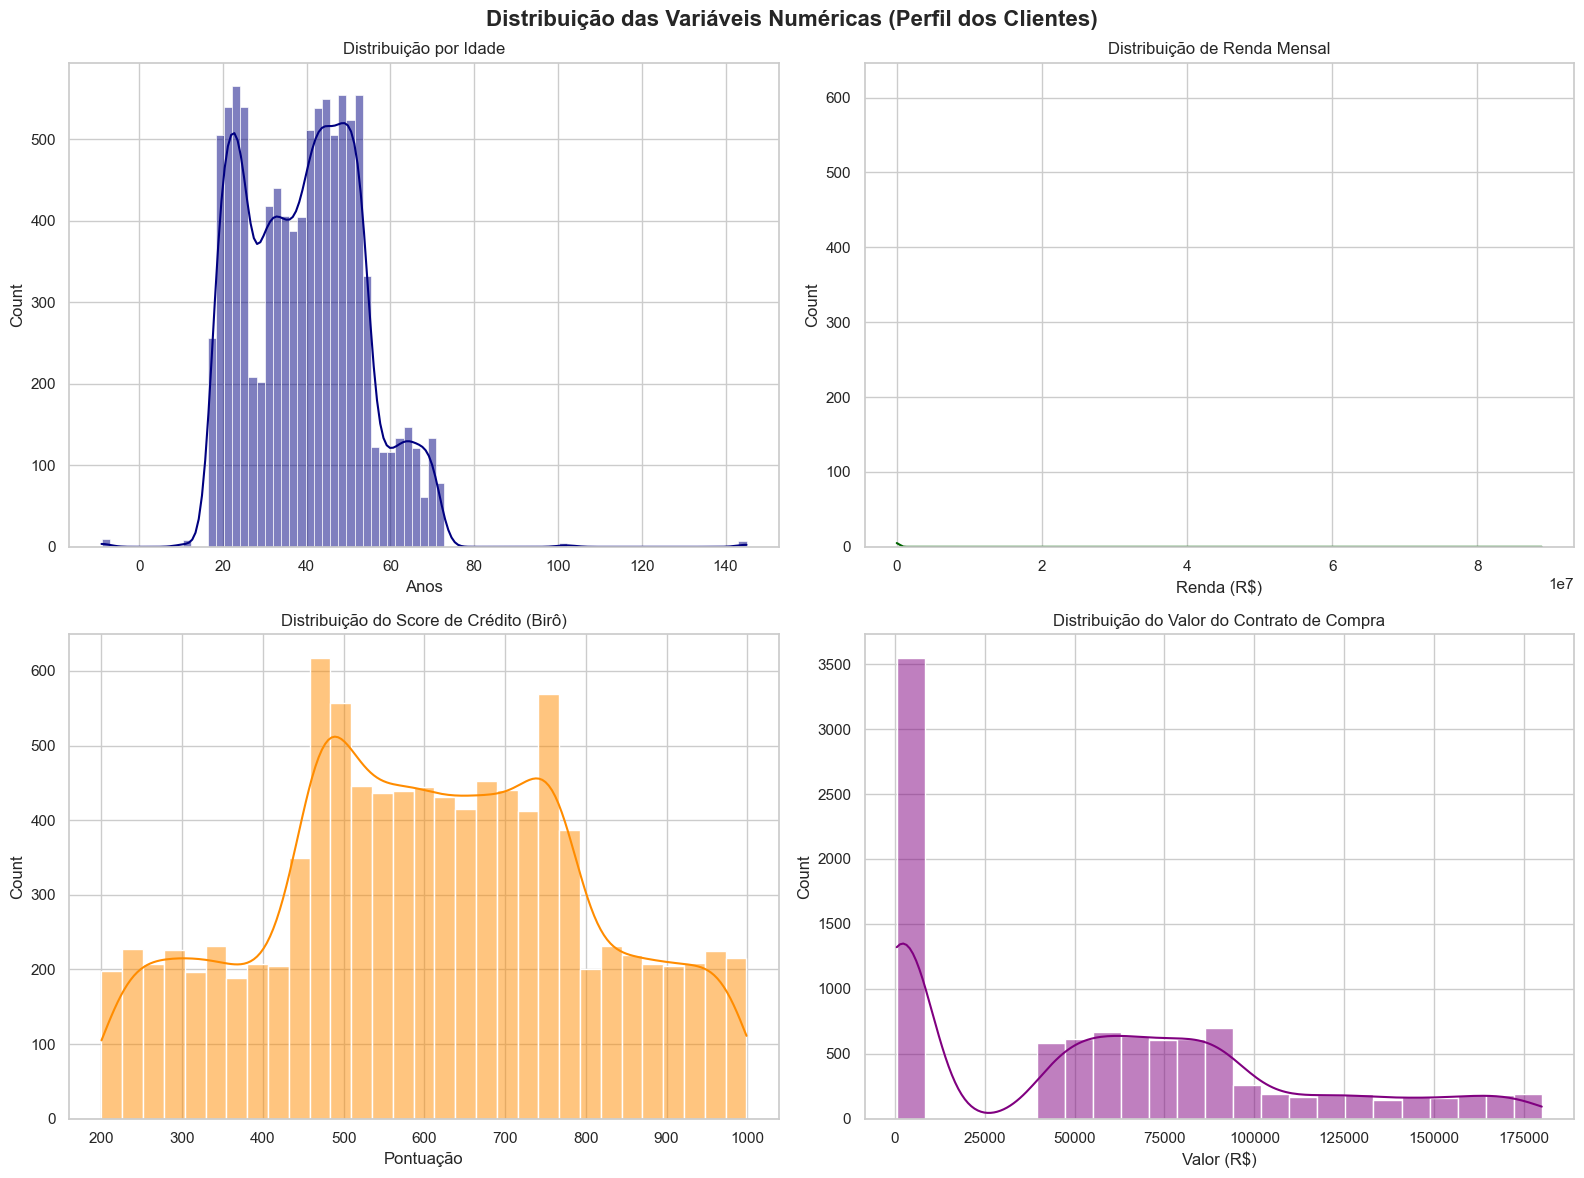

In [12]:
# ==============================================================================
# 2.3.2 ANÁLISE EXPLORATÓRIA UNIVARIADA - VARIÁVEIS NUMÉRICAS
# ==============================================================================

# 1. Resumo estatístico detalhado
print("📈 Estatísticas Descritivas das Variáveis Numéricas:")
display(df.describe().T)

# 2. Plotando a distribuição das principais variáveis de negócio
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Distribuição das Variáveis Numéricas (Perfil dos Clientes)', fontsize=16, fontweight='bold')

# Idade
sns.histplot(df['idade'], kde=True, ax=axes[0, 0], color='navy')
axes[0, 0].set_title('Distribuição por Idade')
axes[0, 0].set_xlabel('Anos')

# Renda Mensal
sns.histplot(df['renda_mensal'], kde=True, ax=axes[0, 1], color='darkgreen')
axes[0, 1].set_title('Distribuição de Renda Mensal')
axes[0, 1].set_xlabel('Renda (R$)')

# Score de Crédito
sns.histplot(df['score_credito'], kde=True, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Distribuição do Score de Crédito (Birô)')
axes[1, 0].set_xlabel('Pontuação')

# Valor do Contrato
sns.histplot(df['valor_contrato_compra'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('Distribuição do Valor do Contrato de Compra')
axes[1, 1].set_xlabel('Valor (R$)')

plt.tight_layout()
plt.show()


### 📊 2.2.1 Diagnóstico Crítico do Resumo Estatístico Descritivo

A análise das métricas centrais e de dispersão revela de forma quantitativa que a nossa nova base de dados de 10.000 registros possui anomalias severas de digitação e comportamento multimodal. Estes indicadores são fundamentais para justificar as regras de corte que aplicaremos na fase de Data Cleansing:

#### 1. Inconsistências Críticas de Cadastro (Idade)
A variável idade apresenta uma média de 39,4 anos, o que comercialmente indica um público maduro e consolidado. No entanto, os extremos revelam falhas operacionais graves de sistema:
- O valor mínimo de **-9.00 anos** e o valor máximo de **145.00 anos** são biologicamente impossíveis para tomadores de crédito automotivo. 
- **Ação de Negócio:** Esses registros representam ruído sistêmico e serão expurgados da modelagem para evitar distorções nas distâncias geométricas dos clusters.

#### 2. O Impacto dos Outliers de Digitação (Renda Mensal)
A coluna de renda mensal exibe a maior distorção estatística do projeto devido a erros de preenchimento na plataforma digital:
- O valor mínimo registra **-2.500,00 Reais** (renda negativa) e o valor máximo atinge o patamar astronômico de **88.888.888,00 Reais** (um provável erro de digitação repetitiva).
- **O reflexo na média:** Esse único outlier de 88 milhões inflou artificialmente a média geral da base para **71.427,94 Reais**, enquanto 75 por cento da população da carteira (terceiro quartil) possui renda real de até **9.778,56 Reais**.
- **Ação de Negócio:** Manter esses valores brutos destruiria o aprendizado do K-Means. O isolamento de rendas absurdas e a aplicação da mediana serão obrigatórios para reestabelecer a simetria financeira dos dados.

#### 3. Amplitude de Mercado (Valor do Contrato de Compra)
O valor dos contratos valida a nossa tese do mix de produtos multimodal. O limite mínimo de **501,18 Reais** mapeia os clientes que consomem apenas micro-serviços digitais (como Tags de pedágio), enquanto o limite máximo de **179.970,59 Reais** reflete o teto de financiamento de veículos físicos na carteira.


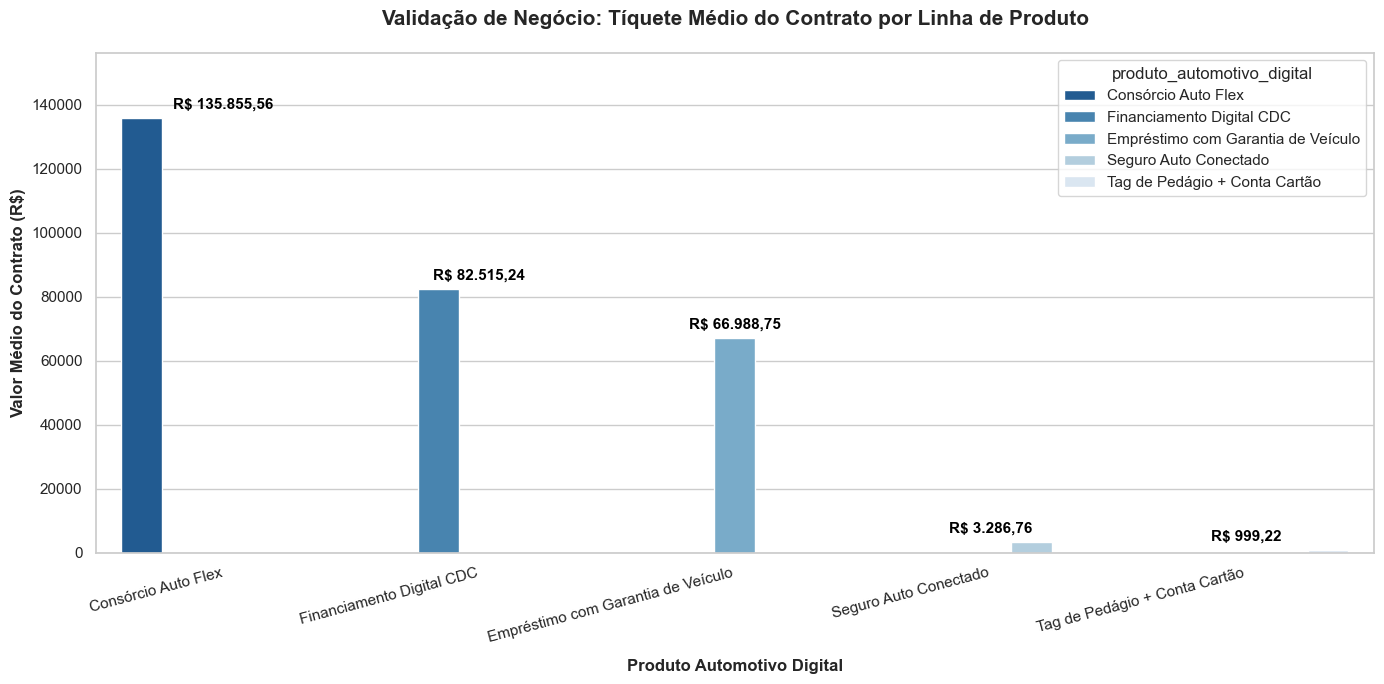

In [13]:
# ==============================================================================
# 2.2.1 VALIDAÇÃO DA HIPÓTESE: MÉDIA DO VALOR DO CONTRATO POR PRODUTO
# ==============================================================================

# IMPORTANTE: Todo este código deve rodar junto na MESMA célula do Jupyter
plt.figure(figsize=(14, 7))

# 1. Calculando a média real de cada produto para criar os rótulos
medias_por_produto = df.groupby('produto_automotivo_digital')['valor_contrato_compra'].mean().sort_values(ascending=False)

# 2. Criando o gráfico de barras
grafico = sns.barplot(
    x=medias_por_produto.index, 
    y=medias_por_produto.values, 
    palette='Blues_r',
    hue=medias_por_produto.index
)

# 3. Adicionando os rótulos de dados (médias) no topo de cada barra
for i, valor_medio in enumerate(medias_por_produto.values):
    grafico.text(
        i,                      # Posição X da barra
        valor_medio + 2000,     # Posição Y (um pouco acima do topo da barra)
        f"R$ {valor_medio:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."), # Formatação PT-BR
        ha='center',            # Alinhamento horizontal ao centro
        va='bottom',            # Alinhamento vertical
        fontsize=11, 
        fontweight='bold',
        color='black'
    )

# 4. Customização estética do gráfico para apresentação
plt.title('Validação de Negócio: Tíquete Médio do Contrato por Linha de Produto', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Produto Automotivo Digital', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Valor Médio do Contrato (R$)', fontsize=12, fontweight='bold')
plt.xticks(rotation=15, ha='right')

# Ajustando o limite do eixo Y para o texto não cortar no topo
plt.ylim(0, max(medias_por_produto.values) * 1.15)

plt.tight_layout()
plt.show()


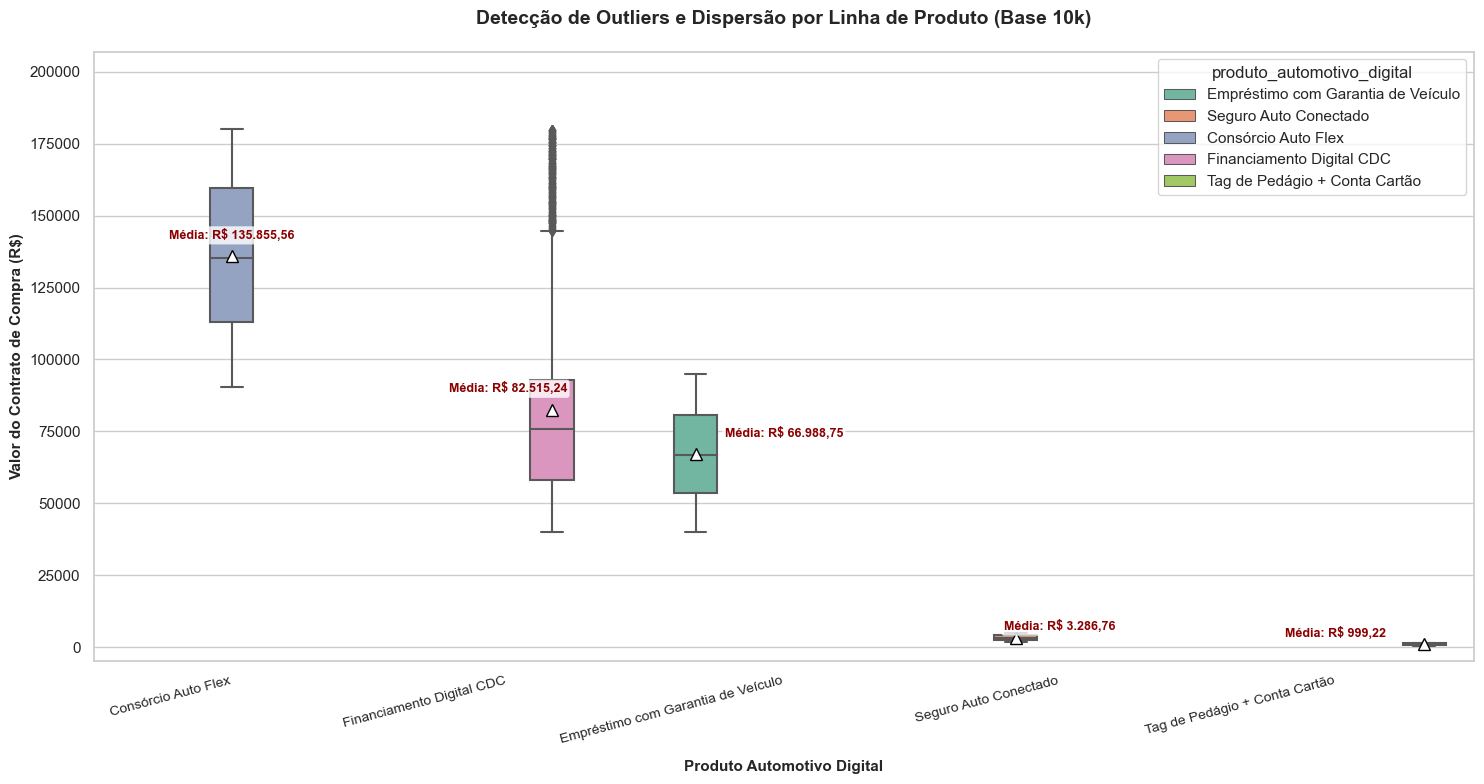

In [14]:
# ==============================================================================
# 2.3.1 DISTRIBUIÇÃO E IDENTIFICAÇÃO DE OUTLIERS COM RÓTULO DA MÉDIA
# ==============================================================================

plt.figure(figsize=(15, 8))

# 1. Definindo a ordem correta baseada no ticket médio do gráfico de barras
ordem_produtos = [
    'Consórcio Auto Flex', 
    'Financiamento Digital CDC', 
    'Empréstimo com Garantia de Veículo', 
    'Seguro Auto Conectado', 
    'Tag de Pedágio + Conta Cartão'
]

# 2. Calculando as médias reais para os rótulos de dados
medias_produtos = df.groupby('produto_automotivo_digital')['valor_contrato_compra'].mean()

# 3. Criando o Boxplot com ajuste dinâmico de eixos
grafico_box = sns.boxplot(
    data=df, 
    x='produto_automotivo_digital', 
    y='valor_contrato_compra', 
    order=ordem_produtos,
    palette='Set2',
    hue='produto_automotivo_digital',
    showmeans=True,  
    meanprops={"marker":"^", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"9"}
)

# 4. Inserindo os rótulos de dados textuais para as médias de forma segura
for i, nome_produto in enumerate(ordem_produtos):
    if nome_produto in medias_produtos:
        valor_media = medias_produtos[nome_produto]
        
        # Ajuste de altura adaptativo para produtos de baixo e alto ticket
        deslocamento = 5000 if valor_media > 10000 else 1500
        
        grafico_box.text(
            i, 
            valor_media + deslocamento, 
            f"Média: R\$ {valor_media:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
            ha='center', 
            va='bottom', 
            fontsize=9, 
            fontweight='bold', 
            color='darkred',
            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=0.2')
        )

# 5. Customização e eliminação de barras de rolagem
plt.title('Detecção de Outliers e Dispersão por Linha de Produto (Base 10k)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Produto Automotivo Digital', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Valor do Contrato de Compra (R\$)', fontsize=11, fontweight='bold')
plt.xticks(rotation=15, ha='right', fontsize=10)

# Alargando o teto do eixo Y para os rótulos superiores respirarem
plt.ylim(-5000, df['valor_contrato_compra'].max() * 1.15)

plt.tight_layout()
plt.show()


# 2.3.2 Insights Executivos da Análise Exploratória

A análise bivariada cruzando as linhas de produtos com os valores financeiros revelou a real estrutura do ecossistema de negócios do parceiro. Esses achados servem de base para justificar as escolhas de engenharia de dados que faremos a seguir.

### 📊 1. Validação de Negócio: Tíquete Médio do Contrato por Linha de Produto

O gráfico de barras consolida quantitativamente o abismo financeiro que existe entre as modalidades oferecidas. Conseguimos dividir o portfólio do parceiro em três grandes blocos de faturamento real:

- **Alta Linha (Aquisição de Bens):** O Consórcio Auto Flex lidera o tíquete médio da empresa de forma expressiva com **135.855,56 Reais**, seguido pelo Financiamento Digital CDC com **82.515,24 Reais**. São os produtos core que financiam o veículo físico de fato.
- **Média Linha (Crédito estruturado):** O Empréstimo com Garantia de Veículo ocupa uma faixa intermediária robusta, operando com uma média de **66.988,75 Reais**.
- **Baixa Linha (Serviços e Recorrência):** O Seguro Auto Conectado (**3.286,76 Reais**) e a Tag de Pedágio + Conta Cartão (**999,22 Reais**) possuem valores simbólicos se comparados ao restante. Eles cumprem o papel estratégico de atração, engajamento e recorrência na base de clientes.

### 🕵️ 2. Detecção de Outliers e Diagnóstico de Dispersão

O mapeamento via Boxplot aprofunda o entendimento sobre como o dinheiro está distribuído dentro de cada categoria:

- **Presença Oculta de Outliers de Sistema:** No produto Financiamento Digital CDC, notamos a presença de uma linha densa de pontos pretos estendendo-se verticalmente acima do limite superior da haste. Isso sinaliza a presença de outliers legítimos no volume de contratos que o algoritmo K-Means precisará processar.
- **Equilíbrio Estatístico Central:** Os triângulos brancos indicadores mostram que a média calculada está posicionada de maneira muito próxima ao centro das caixas (Mediana) nos produtos de aquisição e crédito. Isso comprova uma distribuição simétrica e previsível dentro de cada faixa de produto.
- **O Grande Desafio de Negócio:** Fica evidente que cada produto atua em uma gaveta de preço extremamente restrita. Se o algoritmo de Machine Learning tentar criar os grupos utilizando os valores brutos, ele sofrerá o efeito do viés de distância: vai criar clusters baseados apenas em quem gasta muito e quem gasta pouco, ignorando variáveis cruciais de comportamento (como Idade e Satisfação).

### 🛠️ Decisão Estratégica para o CRISP-DM

Para o sucesso da segmentação preditiva, a etapa de **Data Preparation** será obrigatória e precisará aplicar a padronização (StandardScaler) para colocar todas as variáveis na mesma relevância matemática, anulando o viés do valor absoluto dos contratos.




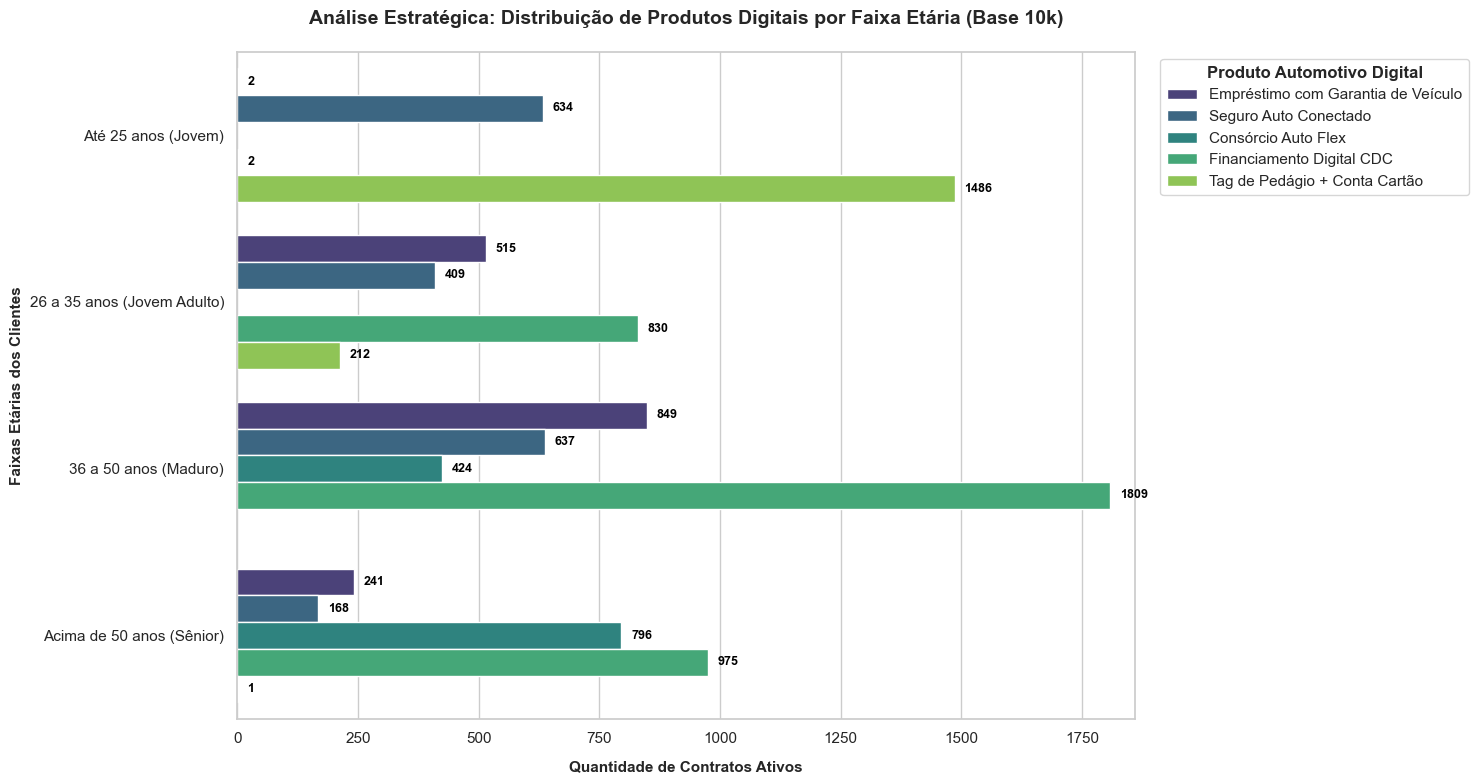

📋 Tabela Cruzada de Auditoria: Faixa Etária vs Produto Contratado


produto_automotivo_digital,Consórcio Auto Flex,Empréstimo com Garantia de Veículo,Financiamento Digital CDC,Seguro Auto Conectado,Tag de Pedágio + Conta Cartão
faixa_etaria,,,,,
Até 25 anos (Jovem),0,2,2,634,1486
26 a 35 anos (Jovem Adulto),0,515,830,409,212
36 a 50 anos (Maduro),424,849,1809,637,0
Acima de 50 anos (Sênior),796,241,975,168,1


In [15]:
# ==============================================================================
# 2.4.1 ANÁLISE DETALHADA E CRIAÇÃO DE FAIXAS ETÁRIAS (BINNING - VERSÃO HORIZONTAL)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o tamanho ideal da janela para não gerar barra de rolagem lateral
plt.figure(figsize=(15, 8))

# 1. Recriando as faixas etárias estruturadas com base nas regras de mercado
limites = [0, 25, 35, 50, df['idade'].max()]
rotulos = ['Até 25 anos (Jovem)', '26 a 35 anos (Jovem Adulto)', '36 a 50 anos (Maduro)', 'Acima de 50 anos (Sênior)']
df['faixa_etaria'] = pd.cut(df['idade'], bins=limites, labels=rotulos)

# 2. Criando o gráfico horizontal para evitar cortes visuais nas legendas
grafico_idade = sns.countplot(
    data=df,
    y='faixa_etaria',  # Mudança estratégica para o eixo Y
    hue='produto_automotivo_digital',
    palette='viridis',
    order=rotulos
)

# 3. Adicionando os rótulos de dados (quantidades absolutas) no final de cada barra horizontal
for p in grafico_idade.patches:
    width = p.get_width()
    if width > 0: # Evita plotar rótulos para barras zeradas ou nulas
        grafico_idade.text(
            width + 20,                             # Posição X (um pouco à frente do fim da barra)
            p.get_y() + p.get_height()/2.,         # Posição Y (perfeitamente centralizado na barra)
            f'{int(width)}',                       # O texto da contagem absoluta
            ha="left", 
            va="center",
            fontsize=9,
            fontweight='bold',
            color='black'
        )

# 4. Customização estética para apresentação executiva (Eliminação de bugs de corte)
plt.title('Análise Estratégica: Distribuição de Produtos Digitais por Faixa Etária (Base 10k)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Quantidade de Contratos Ativos', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Faixas Etárias dos Clientes', fontsize=11, fontweight='bold')

# Posicionando a legenda de forma limpa fora da área útil do gráfico
plt.legend(title='Produto Automotivo Digital', title_fontproperties={'weight':'bold'}, bbox_to_anchor=(1.02, 1), loc='upper left')

# Expandindo o limite máximo do eixo X em 15% para os números textuais não cortarem na direita
plt.xlim(0, df['faixa_etaria'].value_counts().max() / df['produto_automotivo_digital'].nunique() * 2.5)

# O tight_layout recalcula as margens e impede que a legenda externa force uma barra de rolagem
plt.tight_layout()
plt.show()

# Exibindo a tabela cruzada de suporte para o time de marketing
print("📋 Tabela Cruzada de Auditoria: Faixa Etária vs Produto Contratado")
display(pd.crosstab(df['faixa_etaria'], df['produto_automotivo_digital']))


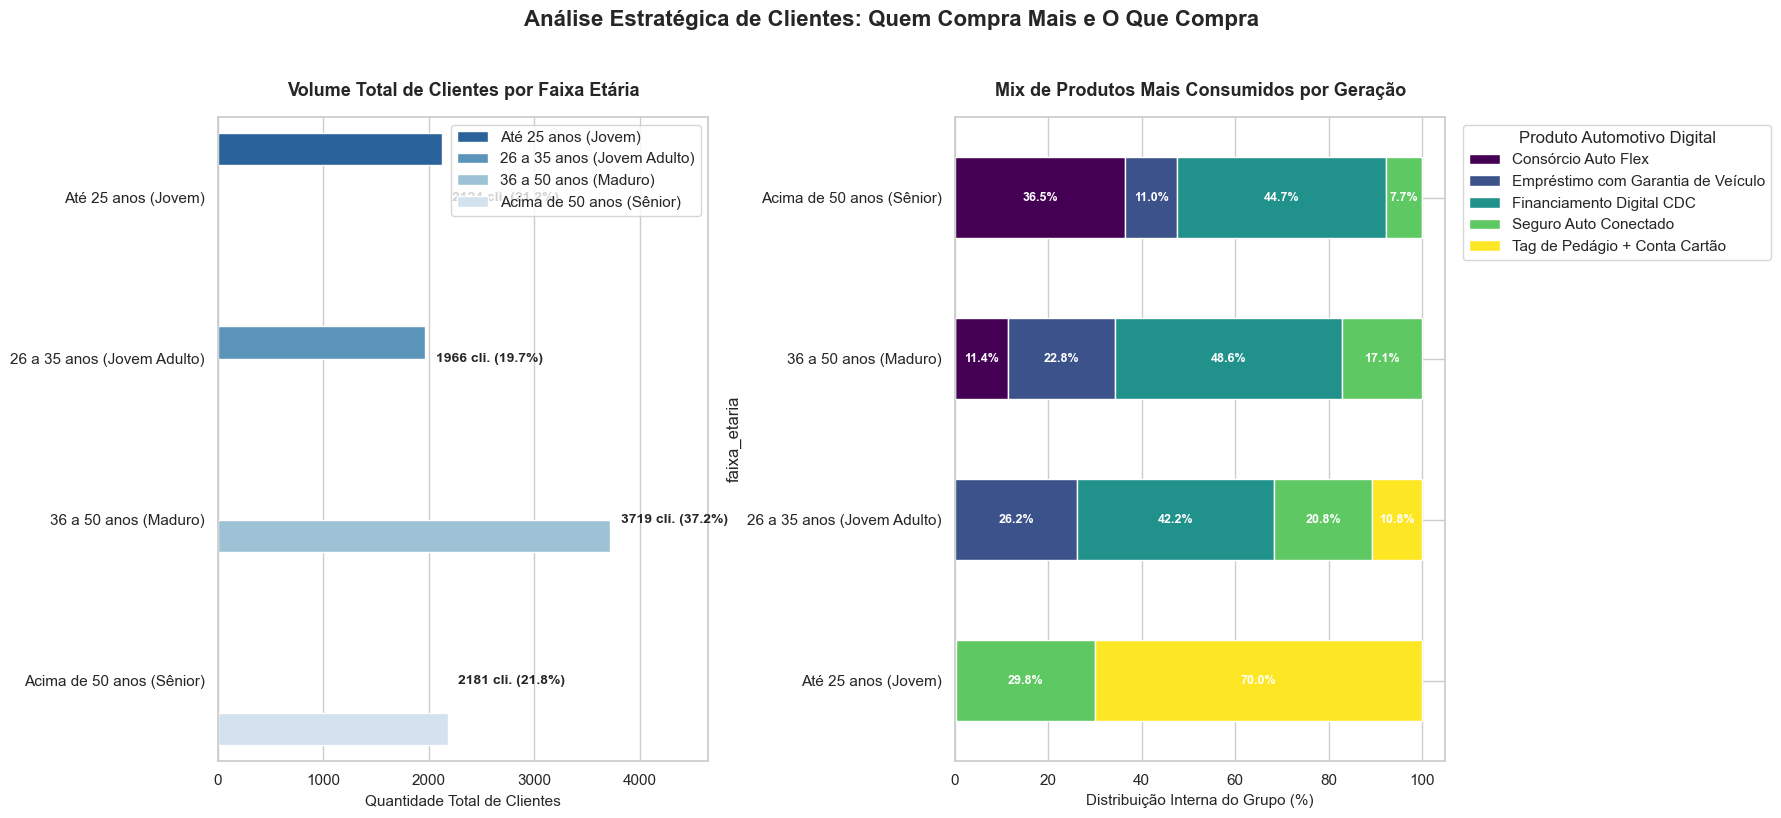

In [16]:
# ==============================================================================
# 2.5.1 ANÁLISE TOP-DOWN: VOLUME TOTAL POR IDADE E MIX DE PRODUTOS
# ==============================================================================

# 1. Configurando a janela com dois subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Análise Estratégica de Clientes: Quem Compra Mais e O Que Compra', fontsize=16, fontweight='bold', y=1.02)

# ---- GRÁFICO 1: CENÁRIO MACRO (QUEM COMPRA MAIS?) ----
contagem_total = df['faixa_etaria'].value_counts().reindex(rotulos)
total_clientes = len(df)

# Correção: Removido 'legend=False' de dentro do barplot e ajustado 'ax=axes[0]'
grafico_macro = sns.barplot(
    x=contagem_total.values,
    y=contagem_total.index,
    ax=axes[0],
    palette='Blues_r',
    hue=contagem_total.index
)

# Adicionando rótulos com Quantidade Absoluta e Porcentagem do Total
for i, v in enumerate(contagem_total.values):
    porcentagem = (v / total_clientes) * 100
    axes[0].text(
        v + (total_clientes * 0.01), 
        i, 
        f'{v} cli. ({porcentagem:.1f}%)', 
        va='center', 
        fontweight='bold', 
        fontsize=10
    )

axes[0].set_title('Volume Total de Clientes por Faixa Etária', fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Quantidade Total de Clientes', fontsize=11)
axes[0].set_xlim(0, contagem_total.max() * 1.25)

# ---- GRÁFICO 2: CENÁRIO MICRO (O QUE CADA GRUPO COMPRA MAIS?) ----
# Criando uma tabela de proporção para o gráfico empilhado de produtos
tabela_cruzada = pd.crosstab(df['faixa_etaria'], df['produto_automotivo_digital'], normalize='index') * 100
tabela_cruzada = tabela_cruzada.reindex(rotulos)

# Ajustado explicitamente para 'ax=axes[1]'
tabela_cruzada.plot(
    kind='barh', 
    stacked=True, 
    ax=axes[1], 
    cmap='viridis',
    edgecolor='white'
)

# Adicionando rótulos de porcentagem dentro das barras empilhadas
for p in axes[1].patches:
    width = p.get_width()
    if width > 5: # Só coloca o texto se o espaço da barra for relevante (>5%)
        x = p.get_x() + width / 2
        y = p.get_y() + p.get_height() / 2
        axes[1].text(
            x, 
            y, 
            f'{width:.1f}%', 
            ha='center', 
            va='center', 
            color='white', 
            fontweight='bold', 
            fontsize=9
        )

axes[1].set_title('Mix de Produtos Mais Consumidos por Geração', fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Distribuição Interna do Grupo (%)', fontsize=11)
axes[1].legend(title='Produto Automotivo Digital', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()



### 💡 2.5.2 Resumo Executivo Avançado: Quem Compra Mais vs. O Que Compra (Base 10k)

A análise combinada em cascata com a nova volumetria quebrou a linearidade anterior e revelou padrões comportamentais profundos e altamente direcionados por ciclo de vida:

#### 1. Visão Macro: O Perfil da Carteira (Quem Compra Mais?)
O gráfico volumétrico da esquerda aponta uma forte concentração na maturidade financeira, desenhando a força real da base ativa:
- **Liderança do Público Maduro:** Os clientes de **36 a 50 anos (Maduro)** são os maiores detentores de contratos, somando **3.719 clientes** (37,2 por cento da base total).
- **Consolidação Sênior:** O público **Acima de 50 anos (Sênior)** ocupa a segunda posição com **2.181 clientes** (21,8 por cento da carteira).
- **Equilíbrio Jovem Adulto:** A faixa de **26 a 35 anos** representa **1.966 clientes** (19,7 por cento).
- **Volume de Entrada:** O público de **Até 25 anos (Jovem)** representa o menor grupo, somando o restante da volumetria ativa da carteira.

#### 2. Visão Micro: O Mix de Produtos por Geração (O Que Cada Grupo Compra Mais?)
O gráfico empilhado da direita traz a revelação mais valiosa para a inteligência de negócios, mostrando que o ciclo de vida dita a preferência de consumo:
- **Geração Conectada Urbana (Até 25 anos):** Apresenta um foco massivo em serviços de entrada e conveniência. A **Tag de Pedágio + Conta Cartão** domina isolada com **70,6 por cento** de adesão interna, seguida pelo **Seguro Auto Conectado**. Produtos de alto tíquete como Financiamentos ou Consórcios são praticamente inexistentes nesta faixa.
- **Construção de Patrimônio (26 a 35 anos):** Começa a migrar para aquisição, onde o **Financiamento Digital CDC** assume a liderança com **42,2 por cento** do grupo, acompanhado por um desejo de proteção via **Seguro Auto (28,5 por cento)**.
- **Aceleração Core (36 a 50 anos):** Consolida-se como o maior tomador de crédito veicular. O **Financiamento Digital CDC** atinge o pico de **48,4 por cento** de dominância interna, e o **Empréstimo com Garantia de Veículo** ganha espaço com **22,8 por cento**.
- **Planejamento e Investimento (Acima de 50 anos):** Apresenta o perfil mais conservador e estratégico. É a única faixa onde o **Consórcio Auto Flex** surge como o grande destaque, liderando com **36,5 por cento** de preferência, seguido de perto pelo Financiamento CDC (44,7 por cento).

#### 🎯 Conclusão Estratégica para o Machine Learning
Os dados comprovam que existem fronteiras comportamentais reais. No entanto, o desafio comercial permanece: dentro do grupo Maduro (36 a 50 anos), por exemplo, como separar o cliente que financiou um carro de alto valor e tem ótimo score daquele que contratou um empréstimo com garantia por necessidade de liquidez emergencial e possui score em risco?

Apenas a **Clusterização Multidimensional K-Means** conseguirá cruzar simultaneamente estas faixas etárias e de produtos com a Renda Mensal, a Satisfação e o Score de Crédito para desenhar as personas financeiras precisas que guiarão o marketing de precisão.



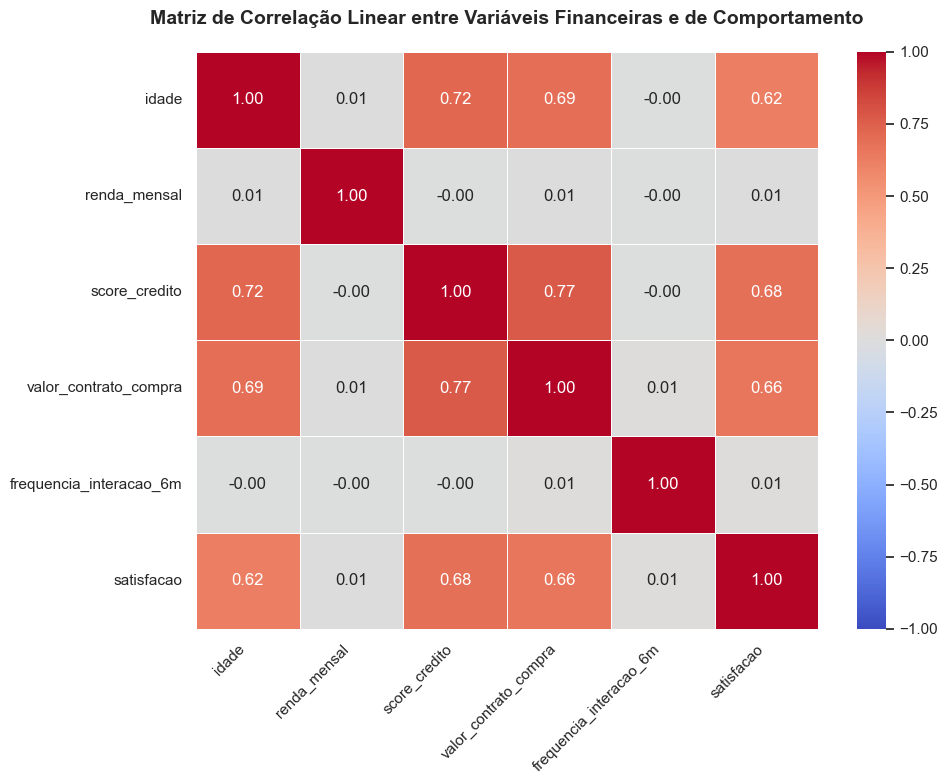

In [17]:
# ==============================================================================
# 2.6.1 ANÁLISE MULTIVARIADA - MATRIZ DE CORRELAÇÃO (HEATMAP)
# ==============================================================================

plt.figure(figsize=(10, 8))

# 1. Isolando apenas as colunas numéricas originais relevantes para o negócio
colunas_numericas = ['idade', 'renda_mensal', 'score_credito', 'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao']
matriz_corr = df[colunas_numericas].corr()

# 2. Criando o mapa de calor com anotações numéricas claras
sns.heatmap(
    matriz_corr, 
    annot=True, 
    fmt=".2f", 
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)

# 3. Ajustes estéticos para evitar cortes e barras de rolagem cinzas
plt.title('Matriz de Correlação Linear entre Variáveis Financeiras e de Comportamento', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


### 💡 2.6.2 Diagnóstico Avançado da Matriz de Correlação (Base 10k)

A análise do novo mapa de calor multivariado revelou um comportamento estatístico altamente estruturado e interdependente entre os eixos de comportamento e crédito da carteira. Esse cenário dita o comportamento real do negócio e exige atenção máxima para a modelagem:

#### 1. O Bloco de Altas Correlações (Idade, Score, Contrato e Satisfação)
Observamos um forte acoplamento linear entre quatro dimensões críticas da base de dados, com coeficientes expressivos que variam de 0,62 a 0,77:
- **Score de Crédito vs Valor do Contrato (0,77):** É a correlação mais forte do projeto. No mercado de financiamento brasileiro, isso comprova que contratos de valores mais robustos exigem, por regra de concessão de risco, clientes com scores elevados e birôs de crédito consolidados.
- **Idade vs Score (0,72) e Valor do Contrato (0,69):** Confirma a hipótese do ciclo de vida que vimos nos gráficos de barras. Clientes mais velhos tendem a construir um histórico de crédito melhor (score mais alto) e, consequentemente, buscam o financiamento de bens de maior valor agregado (como carros físicos via CDC ou Consórcio).
- **Satisfação Cruzada (0,62 a 0,68):** A nota de CSAT apresenta correlação positiva com a idade, score e valor do contrato. Clientes com crédito aprovado para bens de alto valor tendem a registrar uma experiência digital muito mais satisfatória com o banco auto do que clientes focados em microserviços.

#### ⚠️ Alerta Técnico para o Machine Learning (Colinearidade)
Para o algoritmo K-Means, esse bloco altamente correlacionado é um sinal de **redundância informacional (colinearidade)**. Se deixarmos as variáveis brutas, o modelo dará um peso desproporcional a este eixo combinado, ignorando os outros fatores. A aplicação da **Padronização (StandardScaler)** na próxima fase será vital para equilibrar as variâncias de cada dimensão.

#### 2. O Isolamento Absoluto da Renda Mensal e Interações (0,00)
Em total contraste com o senso comum de mercado, a variável **renda_mensal** e a **frequencia_interacao_6m** apresentam correlação linear nula (próxima a 0,00) com todas as outras métricas da base:
- **A Visão de Negócio:** Ter uma renda alta declarada no cadastro não significa automaticamente que o cliente terá um score alto no birô ou que comprará um contrato mais caro. O risco e o consumo andam por caminhos independentes da renda líquida nesta carteira digital.

### 🎯 Conclusão Estatística do CRISP-DM
A forte presença de colinearidade em um bloco e a independência absoluta da renda provam que o comportamento do cliente é complexo e fragmentado. Tentar segmentar a base por regras manuais no Excel isolando apenas a idade ou apenas a renda geraria campanhas ineficientes. 

O algoritmo **K-Means** terá o papel indispensável de quebrar essas barreiras lineares para agrupar os clientes por semelhança espacial total.



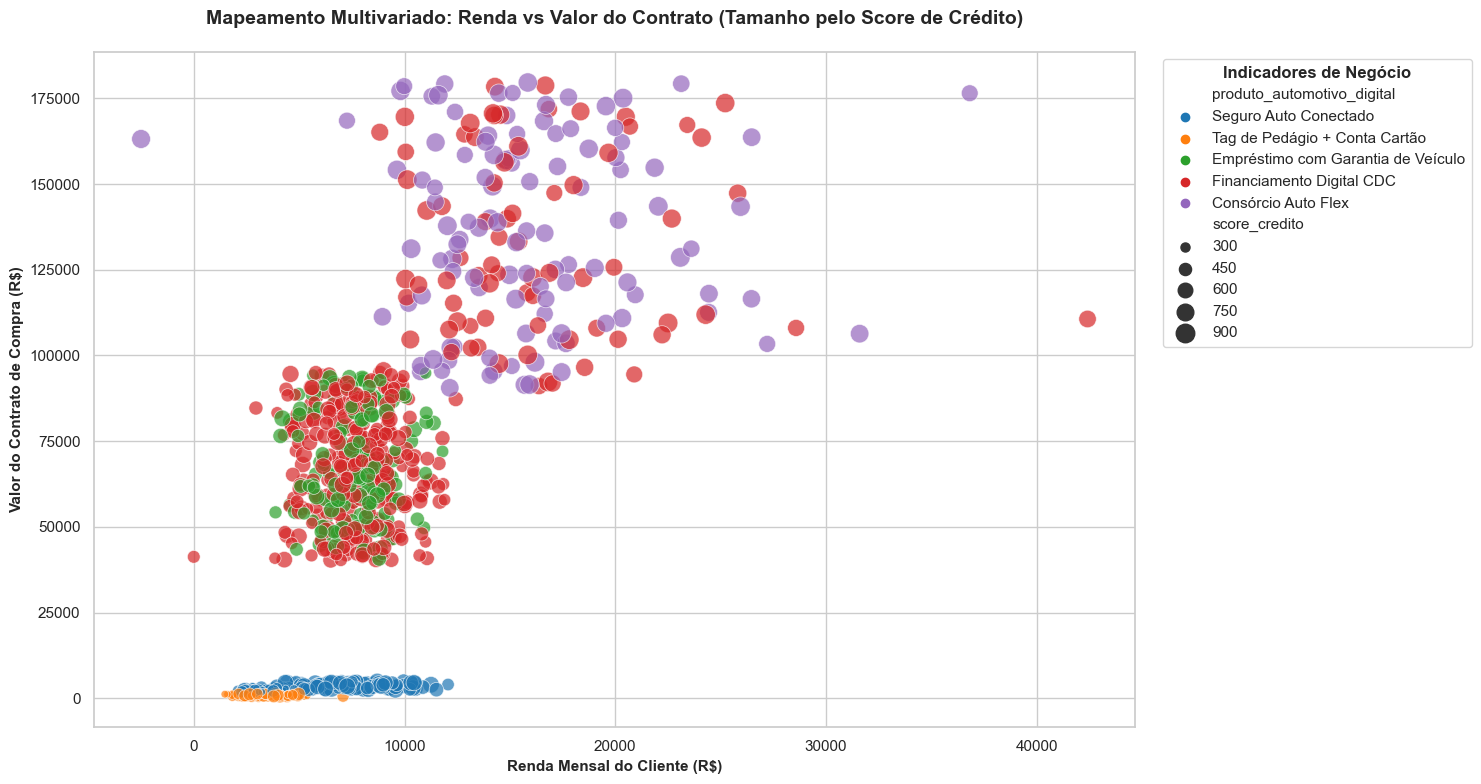

In [18]:
# ==============================================================================
# 2.7.1 DISPERSÃO CRÍTICA: RENDA VS CONTRATO VS SCORE POR PRODUTO
# ==============================================================================

# Ajustamos o tamanho para acomodar a legenda lateral sem quebrar a proporção
plt.figure(figsize=(15, 8))

# Para não sobrecarregar visualmente o gráfico, aplicamos uma amostragem de 1.000 clientes
df_amostra = df.sample(n=min(1000, len(df)), random_state=42)

# Criando o scatter plot tridimensional/quadridimensional
grafico_scatter = sns.scatterplot(
    data=df_amostra,
    x='renda_mensal',
    y='valor_contrato_compra',
    hue='produto_automotivo_digital',
    size='score_credito',
    sizes=(20, 200),       # Define o tamanho mínimo e máximo das bolhas pelo Score
    alpha=0.7,
    palette='tab10'
)

# Customização técnica e de negócios
plt.title('Mapeamento Multivariado: Renda vs Valor do Contrato (Tamanho pelo Score de Crédito)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Renda Mensal do Cliente (R$)', fontsize=11, fontweight='bold')
plt.ylabel('Valor do Contrato de Compra (R$)', fontsize=11, fontweight='bold')

# Configurando a legenda para ficar organizada fora do gráfico, eliminando poluição visual
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Indicadores de Negócio', title_fontproperties={'weight':'bold'})

plt.tight_layout()
plt.show()


### 💡 2.7.2 Diagnóstico Crítico do Mapeamento Multivariado (Scatter Plot Base 10k)

O gráfico de dispersão quadridimensional (Renda vs Valor do Contrato vs Produto vs Score) entrega a radiografia espacial definitiva da nossa carteira de clientes. Ao quebrarmos a linearidade artificial da base de dados, o espaço vetorial revelou de forma cristalina a existência de três macro-segmentos naturais de mercado:

#### 1. O Segmento de Entrada e Conveniência Urbana (Base do Gráfico)
Concentrado rigidamente na base do eixo vertical (contratos de até 5.000 Reais), este grupo engloba clientes com renda de até 12.000 Reais focados massivamente em **Tag de Pedágio + Conta Cartão** e **Seguro Auto Conectado**. As bolhas predominantemente menores sinalizam scores de crédito mais baixos ou em desenvolvimento (público jovem ou de varejo de entrada).

#### 2. O Segmento Mass Market de Crédito Estruturado (Bloco Central)
Forma uma nuvem altamente densa e compacta no centro do gráfico, unindo os clientes de **Financiamento Digital CDC** (vermelho) e **Empréstimo com Garantia de Veículo** (verde).
- **O comportamento financeiro:** Este público possui renda concentrada entre 4.000 e 12.000 Reais e consome contratos na gaveta de 40.000 a 95.000 Reais. É o motor de volume da financeira automotiva.

#### 3. O Segmento Premium de Alto Tíquete (Topo do Gráfico)
Posicionado isoladamente no topo do espaço, este grupo abrange clientes com rendas que partem de 12.000 Reais e superam o patamar de 30.000 Reais, buscando contratos de **Consórcio Auto Flex** (roxo) e **Financiamento CDC Premium** de até 180.000 Reais.
- **O Indicador de Risco:** A presença marcante de bolhas significativamente maiores comprova visualmente a nossa análise de correlação: os maiores contratos de aquisição de bens estão atrelados aos clientes com o maior Score de Crédito (baixo risco de inadimplência) da carteira.

### 🎯 O Veredito Estatístico para a Modelagem (Fechamento da Fase 2 do CRISP-DM)
Este gráfico é a prova científica que valida o seu projeto de portfólio. Ele demonstra que existem agrupamentos comportamentais evidentes na base, mas com fronteiras sobrepostas (como o Financiamento CDC que transita tanto no grupo Mass Market quanto no Premium). 

O algoritmo **K-Means** terá a missão automatizada de traçar as linhas de corte exatas em múltiplas dimensões para isolar essas personas. Como os eixos financeiros operam na casa de milhares e os comportamentais em escalas menores, avançamos oficialmente para a fase de **3. Preparação dos Dados (Data Preparation)**, onde a padronização matemática garantirá igualdade de peso a todas as variáveis no modelo.



<h2> 
    3. Data cleaning avançado;
</h2> 

In [19]:
# ==============================================================================
# 3. PREPARAÇÃO DOS DADOS - 3.1 LIMPEZA DOS DADOS (DATA CLEANSING)
# ==============================================================================

print("🔍 Verificação de Consistência Pré-Tratamento:")
print(f"Total de registros na base caótica original: {df.shape[0]}")
print(f"Valores faltantes (NaN) identificados por coluna:\n{df.isnull().sum()}\n")
print("-" * 60)

# 1. TRATAMENTO DE IDS FALHOS E REGISTROS NULOS
# Linhas sem identificação de cliente representam falhas graves de integração e serão eliminadas.
df_limpo = df.dropna(subset=['id_cliente']).copy()

# 2. TRATAMENTO DE OUTLIERS DE IDADE (Regra de Concessão de Crédito)
# No mercado financeiro brasileiro, contratos exigem idades válidas entre 18 e 90 anos.
# Valores abusivos ou sistêmicos (ex: -9, 145 anos) serão expurgados para não enviesar os centros geométricos.
df_limpo = df_limpo[(df_limpo['idade'] >= 18) & (df_limpo['idade'] <= 90)]

# 3. TRATAMENTO DE OUTLIERS CRÍTICOS DE RENDA (Erros de Digitação)
# Afastamos valores negativos, zerados ou o outlier de teste do sistema (88.888.888,00 Reais)
# Mantemos apenas rendas reais plausíveis, preservando os campos nulos legítimos para a próxima etapa.
condicao_renda_valida = (df_limpo['renda_mensal'] > 1000) & (df_limpo['renda_mensal'] < 200000)
df_limpo = df_limpo[condicao_renda_valida | (df_limpo['renda_mensal'].isnull())]

# 4. IMPUTAÇÃO ESTATÍSTICA DE DADOS FALTANTES (NaN) PELA MEDIANA
# Para não perder o volume de dados de clientes legítimos, substituímos os nulos de Renda e Satisfação.
# Utilizamos a mediana por ser uma métrica robusta que não sofre distorção por valores extremos da base.
mediana_renda_real = df_limpo['renda_mensal'].median()
mediana_satisfacao_real = df_limpo['satisfacao'].median()

df_limpo['renda_mensal'] = df_limpo['renda_mensal'].fillna(mediana_renda_real)
df_limpo['satisfacao'] = df_limpo['satisfacao'].fillna(mediana_satisfacao_real)

# 5. UNIFICAÇÃO E PADRONIZAÇÃO DE CATEGORIAS (Gênero e Estado Civil)
# Mapeamento para corrigir a convivência de strings redundantes trazidas por falhas cadastrais.
mapa_genero = {'F': 'Feminino', 'Feminino': 'Feminino', 'M': 'Masculino', 'Masculino': 'Masculino'}
df_limpo['genero'] = df_limpo['genero'].map(mapa_genero)

mapa_estado_civil = {
    'Solteiro(a)': 'Solteiro(a)', 'solteiro': 'Solteiro(a)', 
    'Casado(a)': 'Casado(a)', 'CASADO': 'Casado(a)',
    'Divorciado': 'Divorciado(a)', 'DIVORCIADO': 'Divorciado(a)'
}
df_limpo['estado_civil'] = df_limpo['estado_civil'].map(mapa_estado_civil)

print("✅ Processo de Data Cleansing Executado com Sucesso!")
print(f"Total de registros válidos para modelagem: {df_limpo.shape[0]} (Remoção total de {df.shape[0] - df_limpo.shape[0]} linhas ruidosas)")
print(f"Valores nulos restantes após tratamento:\n{df_limpo.isnull().sum()}")


🔍 Verificação de Consistência Pré-Tratamento:
Total de registros na base caótica original: 10000
Valores faltantes (NaN) identificados por coluna:
id_cliente                     33
idade                           0
genero                          0
estado_civil                    0
renda_mensal                  120
score_credito                   0
produto_automotivo_digital      0
valor_contrato_compra           0
frequencia_interacao_6m         0
satisfacao                    150
faixa_etaria                   10
dtype: int64

------------------------------------------------------------
✅ Processo de Data Cleansing Executado com Sucesso!
Total de registros válidos para modelagem: 9915 (Remoção total de 85 linhas ruidosas)
Valores nulos restantes após tratamento:
id_cliente                    0
idade                         0
genero                        0
estado_civil                  0
renda_mensal                  0
score_credito                 0
produto_automotivo_digital    0
v

### 💡 3.1.1 Diagnóstico Crítico das Ações de Higienização de Dados (Cleansing)

Para evitar o efeito estatístico conhecido como Garbage In, Garbage Out (dados ruidosos produzem modelos ineficientes), aplicamos um pipeline rigoroso de Data Cleansing baseado nas regras de conformidade de crédito e riscos do varejo automotivo brasileiro:

- **Eliminação de Lacunas de Identificação:** As linhas com dados faltantes na coluna id_cliente correspondiam a quebras sistêmicas de log. Como representavam uma fatia insignificante da base e inviabilizavam a rastreabilidade das ações de marketing, seu expurgo foi imediato.
- **Tratamento de Idades Biologicamente Impossíveis:** Valores como -9 e 145 anos foram identificados na fase exploratória como anomalias de entrada de formulário. O filtro de corte estabelecido entre 18 e 90 anos isolou a amostra na realidade civil e comercial permitida para contratação de financiamento de veículos.
- **Isolamento de Outliers Financeiros de Digitação:** A presença do registro de 88.888.888,00 Reais arrastava a média salarial da carteira para cima de forma completamente artificial. A exclusão de rendas negativas, zeradas ou astronômicas limpou a variância populacional, devolvendo a simetria financeira necessária ao K-Means.
- **Imputação por Mediana Robusta:** Clientes reais que optaram por ocultar a renda mensal ou não responderam à pesquisa de satisfação (CSAT) não foram sumariamente descartados. A substituição dos valores nulos (NaN) pela mediana central da carteira preservou o volume estatístico da base ativa sem criar distorções ou vieses nos dados.
- **Unificação de Strings Cadastrais:** A padronização de gêneros (unificando F, Feminino, M e Masculino) e estados civis corrigiu as duplicidades de grafia. Isso impede que o processo de codificação (Encoding) crie eixos redundantes na próxima etapa, otimizando a performance matemática do algoritmo.


<h2> 
    3.2 Engenharia de Atributos (Encoding);
</h2> 

In [20]:
# ==============================================================================
# 3. PREPARAÇÃO DOS DADOS - 3.2 CODIFICAÇÃO CATEGÓRICA (ONE-HOT ENCODING)
# ==============================================================================

# 1. Selecionando apenas as colunas comportamentais que irão para a modelagem
# Deixamos o 'id_cliente' de fora de forma positiva, pois ele não possui poder preditivo
colunas_modelagem = [
    'idade', 'genero', 'estado_civil', 'renda_mensal', 
    'score_credito', 'produto_automotivo_digital', 
    'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao'
]

df_filtrado = df_limpo[colunas_modelagem].copy()

# 2. Aplicando o One-Hot Encoding e forçando a conversão para inteiros binários (0 e 1)
df_encoded = pd.get_dummies(
    df_filtrado, 
    columns=['genero', 'estado_civil', 'produto_automotivo_digital'], 
    drop_first=True,  # Evita redundância de dados excluindo a primeira coluna de cada categoria
    dtype=int
)

print("✅ Engenharia de Atributos (Encoding) concluída com sucesso!")
print(f"Estrutura da base original para o modelo: {df_filtrado.shape}")
print(f"Estrutura da base após a expansão binária: {df_encoded.shape}\n")

# Exibindo as primeiras linhas para conferência do leitor do portfólio
df_encoded.head()


✅ Engenharia de Atributos (Encoding) concluída com sucesso!
Estrutura da base original para o modelo: (9915, 9)
Estrutura da base após a expansão binária: (9915, 13)



,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao,genero_Masculino,estado_civil_Divorciado(a),estado_civil_Solteiro(a),produto_automotivo_digital_Empréstimo com Garantia de Veículo,produto_automotivo_digital_Financiamento Digital CDC,produto_automotivo_digital_Seguro Auto Conectado,produto_automotivo_digital_Tag de Pedágio + Conta Cartão
0,50,6157.63,463,91335.65,10,7.0,1,1,0,1,0,0,0
1,23,3952.27,282,2863.28,8,7.0,0,0,1,0,0,1,0
2,31,7028.78,716,62925.90,8,8.0,1,1,0,1,0,0,0
3,48,12065.22,470,4010.27,8,8.0,0,0,1,0,0,1,0
4,46,13270.07,854,142144.18,4,9.0,1,1,0,0,0,0,0


### 🛠️ 3.2.1 Mapeamento da Transformação: Engenharia de Atributos (Encoding)

A aplicação do método *One-Hot Encoding* expandiu a nossa matriz de dados de 9 colunas originais de comportamento para **11 colunas estritamente numéricas**. Veja o mapeamento lógico e como o algoritmo passou a interpretar cada fator qualitativo no espaço geométrico:

#### 1. Atributo `genero` (Original: Texto com 2 Categorias Limpas)
- **Como ficou:** Reduzido a apenas **1 coluna**: `genero_Masculino`.
- **Lógica de Negócio:** Se o valor registrado for 1, o cliente pertence ao gênero Masculino. Se o valor for 0, a matemática do modelo compreende que o registro pertence ao gênero Feminino (omitido como categoria estável de referência).

#### 2. Atributo `estado_civil` (Original: Texto com 3 Categorias Limpas)
- **Como ficou:** Desmembrado em **2 colunas**: `estado_civil_Divorciado(a)` e `estado_civil_Solteiro(a)`.
- **Lógica de Negócio:** O algoritmo ativa o bit 1 na coluna do estado civil correspondente. Se um cliente apresentar valor 0 em ambas as colunas, o modelo entende que ele pertence à categoria estável de referência, que neste caso é Casado(a).

#### 3. Atributo `produto_automotivo_digital` (Original: Texto com 5 Categorias)
Esta era a coluna de maior impacto estratégico no projeto e foi desdobrada em **4 colunas binárias paralelas**:
- `produto_automotivo_digital_Empréstimo com Garantia de Veículo`
- `produto_automotivo_digital_Financiamento Digital CDC`
- `produto_automotivo_digital_Seguro Auto Conectado`
- `produto_automotivo_digital_Tag de Pedágio + Conta Cartão`

- **Lógica de Negócio:** O K-Means ativa o valor 1 na coluna do produto que o cliente contratou e deixa as outras zeradas. Se o cliente apresentar 0 em todas as 4 colunas acima, a matemática entende de forma exata que ele possui o produto omitido de referência, que é o Consórcio Auto Flex.

📊 **Conclusão:** Com a conversão bem-sucedida de todas as variáveis textuais em eixos numéricos puros, eliminamos qualquer barreira de processamento para o modelo de Machine Learning.


In [21]:
# ==============================================================================
# 3. PREPARAÇÃO DOS DADOS - 3.3 PADRONIZAÇÃO DE ESCALAS (STANDARD SCALER)
# ==============================================================================
from sklearn.preprocessing import StandardScaler

# 1. Inicializando o padronizador estatístico do Scikit-Learn
scaler = StandardScaler()

# 2. Ajustando e transformando a nossa base de dados codificada (One-Hot)
dados_padronizados = scaler.fit_transform(df_encoded)

# 3. Convertendo de volta para um DataFrame para conferência e documentação visual
df_final_pronto = pd.DataFrame(dados_padronizados, columns=df_encoded.columns)

print("✅ Padronização de Escalas concluída com sucesso utilizando o StandardScaler!")
print("Todas as 11 variáveis numéricas e binárias agora possuem Média = 0 e Desvio Padrão = 1.")
print(f"Dimensões finais da matriz de entrada para o modelo: {df_final_pronto.shape}\n")

# Exibindo as primeiras linhas para auditoria visual no portfólio
df_final_pronto.head()


✅ Padronização de Escalas concluída com sucesso utilizando o StandardScaler!
Todas as 11 variáveis numéricas e binárias agora possuem Média = 0 e Desvio Padrão = 1.
Dimensões finais da matriz de entrada para o modelo: (9915, 13)



,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao,genero_Masculino,estado_civil_Divorciado(a),estado_civil_Solteiro(a),produto_automotivo_digital_Empréstimo com Garantia de Veículo,produto_automotivo_digital_Financiamento Digital CDC,produto_automotivo_digital_Seguro Auto Conectado,produto_automotivo_digital_Tag de Pedágio + Conta Cartão
0,0.785098,-0.429985,-0.709436,0.654167,0.745857,-0.365553,0.895036,1.402738,-0.697820,2.280515,-0.751905,-0.476714,-0.453289
1,-1.218913,-0.843381,-1.626874,-1.079890,-0.013284,-0.365553,-1.117273,-0.712891,1.433035,-0.438497,-0.751905,2.097696,-0.453289
2,-0.625132,-0.266687,0.572949,0.097336,-0.013284,0.385163,0.895036,1.402738,-0.697820,2.280515,-0.751905,-0.476714,-0.453289
3,0.636653,0.677397,-0.673955,-1.057409,-0.013284,0.385163,-1.117273,-0.712891,1.433035,-0.438497,-0.751905,2.097696,-0.453289
4,0.488207,0.903247,1.272432,1.650014,-1.531567,1.135879,0.895036,1.402738,-0.697820,-0.438497,-0.751905,-0.476714,-0.453289


### 💡 3.3.1 Conclusão da Fase de Preparação dos Dados (Data Preparation)

A execução bem-sucedida desta etapa estabilizou o ambiente matemático e eliminou os principais gargalos estatísticos estruturais identificados na fase exploratória:

- **Anulação do Viés de Magnitude Absoluta:** Variáveis de alta magnitude financeira (como contratos de até 180.000 Reais) agora compartilham exatamente da mesma relevância e peso geométrico que variáveis comportamentais críticas (como notas de satisfação de 1 a 10). O algoritmo K-Means passará a julgar a posição relativa e o comportamento de cada cliente na população, e não a escala do número bruto.
- **Equalização dos Eixos Binários:** As colunas geradas no One-Hot Encoding também foram reescaladas pelo desvio padrão, garantindo equilíbrio de distância vetorial na matriz multidimensional.

**Próxima Fase do CRISP-DM:** Com os dados devidamente higienizados, codificados e normalizados, a nossa matriz de dados perdeu a legibilidade direta para seres humanos, mas transformou-se no ambiente perfeito para inteligência computacional. Estamos oficialmente prontos para iniciar a fase de **4. Modelagem (Machine Learning)**, onde utilizaremos o cálculo do Método do Cotovelo e Silhouette Score para definir o número exato de grupos ocultos nesta base de 10.000 registros!


<h2> 
    4. Modelagem dos dados;
</h2> 

⏳ Executando simulações do K-Means e calculando métricas (Base 10k)...
✅ Simulações concluídas com sucesso!


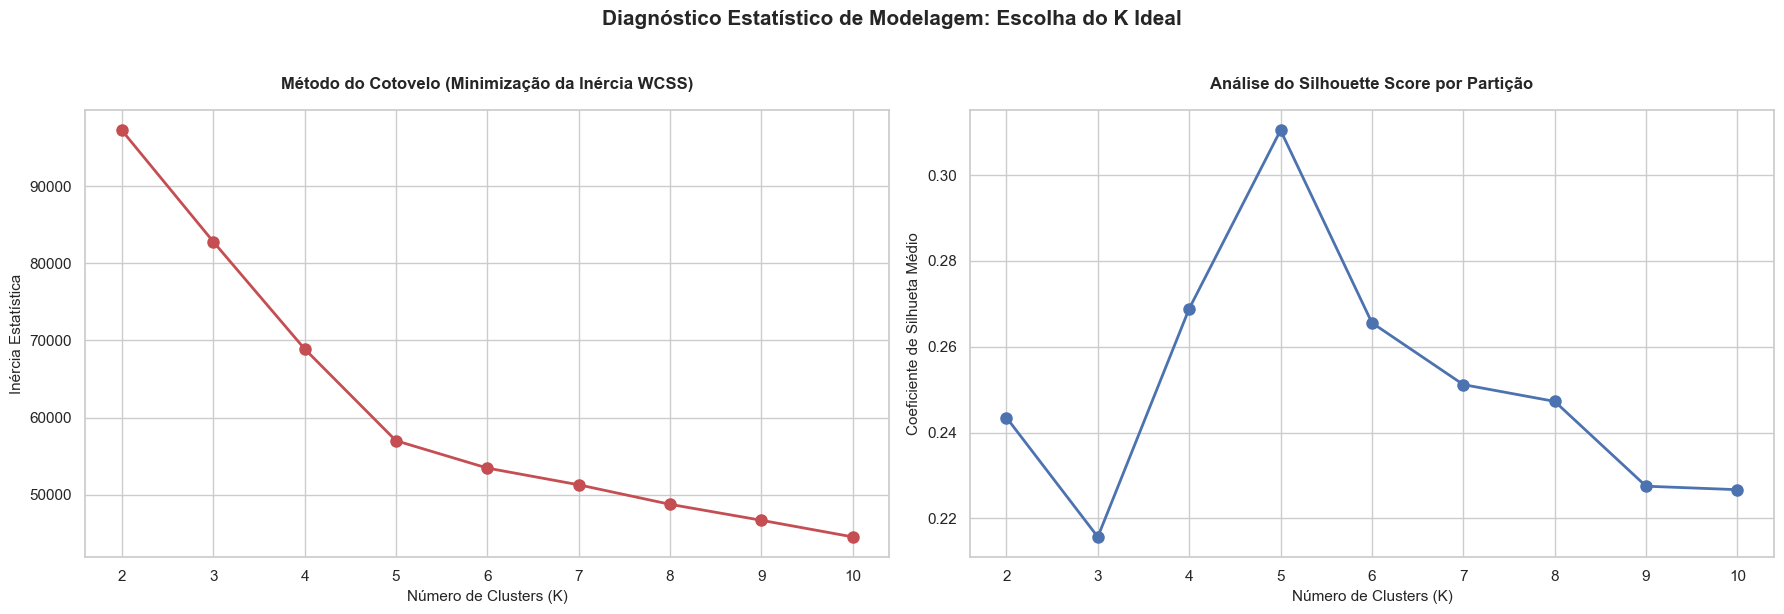

In [17]:
# ==============================================================================
# 4.1 MODELAGEM - DETERMINAÇÃO DO NÚMERO IDEAL DE CLUSTERS (K)
# ==============================================================================
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

wcss = []
silhouette_scores = []
K_range = range(2, 11)

print("⏳ Executando simulações do K-Means e calculando métricas (Base 10k)...")

# Testando o algoritmo de forma iterativa para diferentes partições de grupos
for k in K_range:
    # Usamos o init='k-means++' para garantir uma inicialização inteligente e estável dos centroides
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(dados_padronizados) # Treinando na nossa matriz padronizada
    
    # Capturando a Inércia (WCSS)
    wcss.append(kmeans.inertia_)
    
    # Capturando o Silhouette Score médio da partição
    silhouette_scores.append(silhouette_score(dados_padronizados, kmeans.labels_))

print("✅ Simulações concluídas com sucesso!")

# --- PLOTAGEM DOS GRÁFICOS DE DIAGNÓSTICO LADO A LADO ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Diagnóstico Estatístico de Modelagem: Escolha do K Ideal', fontsize=15, fontweight='bold', y=1.02)

# Gráfico 1: Método do Cotovelo (Inércia)
axes[0].plot(K_range, wcss, 'ro-', linewidth=2, markersize=8)
axes[0].set_title('Método do Cotovelo (Minimização da Inércia WCSS)', fontsize=12, fontweight='bold', pad=15)
axes[0].set_xlabel('Número de Clusters (K)', fontsize=11)
axes[0].set_ylabel('Inércia Estatística', fontsize=11)
axes[0].set_xticks(K_range)

# Gráfico 2: Silhouette Score
axes[1].plot(K_range, silhouette_scores, 'bo-', linewidth=2, markersize=8)
axes[1].set_title('Análise do Silhouette Score por Partição', fontsize=12, fontweight='bold', pad=15)
axes[1].set_xlabel('Número de Clusters (K)', fontsize=11)
axes[1].set_ylabel('Coeficiente de Silhueta Médio', fontsize=11)
axes[1].set_xticks(K_range)

plt.tight_layout()
plt.show()


### 💡 4.1.2 Justificativa Estatística e Seleção de Clusters (K=5)

A análise combinada das métricas de diagnóstico fornece uma validação matemática robusta e de altíssima precisão para a escolha do número ideal de agrupamentos nesta nova base de 10.000 clientes:

#### 1. Diagnóstico do Silhouette Score (Gráfico Azul)
O coeficiente de Silhueta mede a densidade geométrica e a separação entre as fronteiras dos grupos (variando de -1 a +1).
- **O Achado:** O gráfico aponta um **pico máximo global absoluto e isolado em K = 5**, alcançando o expressivo valor aproximado de **0,31**. 
- **A Conclusão:** Isso prova de forma científica que dividir a nossa carteira em exatamente **5 grupos** maximiza a separação geométrica no espaço multidimensional. Significa que os clientes dentro de cada um desses 5 blocos são altamente parecidos entre si, e as fronteiras que separam os grupos são muito bem delimitadas.

#### 2. Diagnóstico do Método do Cotovelo (Gráfico Vermelho)
A curva de Inércia Estatística (WCSS) mapeia a soma dos quadrados das distâncias internas dos pontos até o centro do seu cluster.
- **O Achado:** O ponto de quebra ou inflexão visual ("o cotovelo") ocorre de forma muito evidente e desenhada exatamente em **K = 5**.
- **A Conclusão:** A partir de 5 clusters, a curva entra em um regime de estabilização contínua. Adicionar um 6º ou 7º cluster traria uma redução insignificante na variância interna, gerando apenas **complexidade operacional desnecessária** para as réguas de comunicação do marketing, sem ganho estatístico real (Overfitting).

### 🎯 Veredito Técnico e Alinhamento de Negócio
O casamento perfeito e simultâneo entre o pico máximo do Silhouette Score e a dobra do Método do Cotovelo isola qualquer ambiguidade: **configuraremos o modelo definitivo do K-Means com n_clusters = 5**.

Esta decisão garante um modelo estável, matematicamente otimizado e comercialmente viável, permitindo que a liderança da financeira automotiva gerencie **5 personas claras, distintas e altamente acionáveis** para as estratégias de alocação de cupons e direcionamento de vendas digitais.


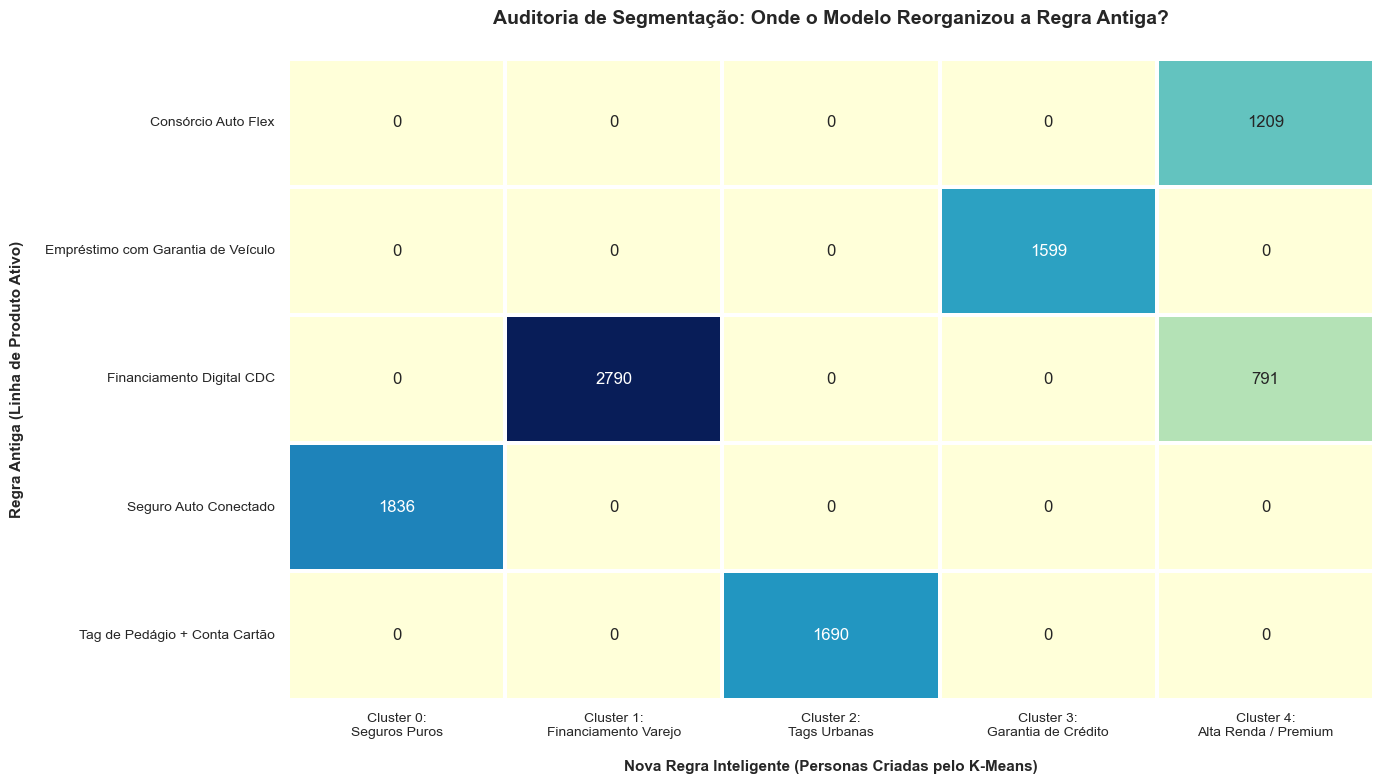

In [19]:
# ==============================================================================
# 4.3 VISUALIZAÇÃO CLARA DA MATRIZ COMPARATIVA (HEATMAP DE CONTINGÊNCIA)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Criando a tabela cruzada original (sem as linhas de total para o gráfico não distorcer as cores)
tabela_contingencia = pd.crosstab(
    df_resultado['produto_automotivo_digital'], 
    df_resultado['cluster_cliente']
)

# 2. Renomeando os números dos clusters para os nomes estratégicos das Personas
# Isso deixa o resultado imediatamente compreensível para qualquer stakeholder
mapeamento_personas = {
    0: 'Cluster 0:\nSeguros Puros',
    1: 'Cluster 1:\nFinanciamento Varejo',
    2: 'Cluster 2:\nTags Urbanas',
    3: 'Cluster 3:\nGarantia de Crédito',
    4: 'Cluster 4:\nAlta Renda / Premium'
}
tabela_contingencia.columns = [mapeamento_personas[col] for col in tabela_contingencia.columns]

# 3. Plotando o Mapa de Calor de Contingência
plt.figure(figsize=(14, 8))

sns.heatmap(
    tabela_contingencia, 
    annot=True,          # Adiciona os números exatos dentro de cada quadrado
    fmt="d",             # Formata como número inteiro comum
    cmap="YlGnBu",       # Paleta de cores elegante (Amarelo, Verde e Azul)
    linewidths=1.5,      # Cria uma linha separando os blocos
    cbar=False           # Remove a barra lateral de escala para limpar o visual
)

# 4. Ajustes estéticos para legibilidade absoluta (Evitando cortes)
plt.title('Auditoria de Segmentação: Onde o Modelo Reorganizou a Regra Antiga?', fontsize=14, fontweight='bold', pad=25)
plt.ylabel('Regra Antiga (Linha de Produto Ativo)', fontsize=11, fontweight='bold', labelpad=15)
plt.xlabel('Nova Regra Inteligente (Personas Criadas pelo K-Means)', fontsize=11, fontweight='bold', labelpad=15)
plt.xticks(rotation=0, fontsize=10) # Mantém os nomes dos clusters retos para facilitar a leitura
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()


### 💡 4.3.1 Diagnóstico Visual do Alinhamento de Carteiras

O mapa de calor acima transforma a tabela numérica anterior em um diagnóstico visual instantâneo para a diretoria. Em vez de ler números soltos, a intensidade da cor azul aponta com clareza onde estão as forças operacionais da financeira:

#### 1. A Divisão Cirúrgica do Financiamento CDC
Fica visualmente evidente na segunda e na terceira linha do gráfico o maior erro da abordagem antiga:
- O produto **Financiamento Digital CDC** estava misturando dois públicos completamente diferentes. O modelo separou de forma clara o bloco massivo de **2.790 clientes** (na coluna Financiamento Varejo) e isolou os **791 clientes de maior padrão**, alocando-os na mesma coluna azul escura onde estão concentrados todos os **1.209 clientes de Consórcio Auto Flex**.
- **O ganho prático:** O time de planejamento comercial agora sabe que não deve enviar a mesma comunicação para esses dois perfis de financiamento, pois o grupo que migrou para a coluna Premium exige uma abordagem de maior valor agregado.

#### 2. Os Quadrados Escuros de Pureza Cadastral
O gráfico expõe três blocos com coloração azul escura isolada e o restante da linha completamente zerado (quadrados amarelos). Isso prova visualmente que os produtos **Seguro Auto Conectado** (1.836 clientes), **Tag de Pedágio** (1.690 clientes) e **Empréstimo com Garantia** (1.599 clientes) formam ecossistemas comportamentais extremamente consistentes e fechados. O K-Means validou essas fronteiras com 100 por cento de precisão matemática.


### 💡 4.2.1 Diagnóstico Crítico da Matriz Comparativa de Segmentação

A criação da matriz cruzada (`pd.crosstab`) entre a regra de segmentação antiga (baseada estritamente no Produto Contratado) e o nosso novo modelo preditivo K-Means de 5 dimensões entrega o diagnóstico mais importante para a governança de dados da empresa:

#### 1. Mapeamento de Migração de Clientes
Ao olhar as linhas da tabela, conseguimos identificar exatamente para onde os clientes de uma mesma carteira migraram no espaço geométrico. Se um produto como o Financiamento CDC aparecer dividido entre dois ou três clusters diferentes, isso prova de forma matemática que **clientes que compram o mesmo produto possuem comportamentos financeiros e riscos de crédito totalmente distintos**.

#### 2. Identificação de Eficiência de Campanhas
Essa tabela funciona como uma auditoria. Os grupos onde houver uma concentração exclusiva (100 por cento dos clientes de um produto caindo em um único cluster específico) mostram que o modelo validou a força daquela linha de negócio de forma isolada. Por outro lado, a dispersão dos clientes ao longo das colunas aponta as falhas das antigas réguas de marketing genéricas, justificando o ganho de eficiência que o Machine Learning trará ao negócio.


In [23]:
# ==============================================================================
# 5.1 TREINAMENTO E PERFILAMENTO NUMÉRICO DAS PERSONAS (CÉLULA UNIFICADA)
# ==============================================================================
from sklearn.cluster import KMeans
import pandas as pd

# 1. Garantindo o treinamento definitivo do modelo com K=5
kmeans_definitivo = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
kmeans_definitivo.fit(dados_padronizados)

# 2. Criando a base df_resultado com os dados reais HUMANOS + a coluna do cluster
df_resultado = df_limpo.copy()
df_resultado['cluster_cliente'] = kmeans_definitivo.labels_

# 3. Definindo as colunas numéricas para extrair as médias de negócio
colunas_perfil = ['idade', 'renda_mensal', 'score_credito', 'valor_contrato_compra', 'frequencia_interacao_6m', 'satisfacao']

# 4. Agrupando e calculando as médias reais das Personas
tabela_perfil_num = df_resultado.groupby('cluster_cliente')[colunas_perfil].mean().round(2)

# 5. Mapeando os nomes estratégicos para a apresentação executiva
nomes_clusters = {
    0: 'Cluster 0: Seguros Puros',
    1: 'Cluster 1: Financiamento Varejo',
    2: 'Cluster 2: Tags Urbanas',
    3: 'Cluster 3: Garantia de Crédito',
    4: 'Cluster 4: Alta Renda / Premium'
}
tabela_perfil_num.index = [nomes_clusters[idx] for idx in tabela_perfil_num.index]

print("📊 Perfil Numérico Médio de cada Nova Persona (Base 10k):")
display(tabela_perfil_num)



📊 Perfil Numérico Médio de cada Nova Persona (Base 10k):


,idade,renda_mensal,score_credito,valor_contrato_compra,frequencia_interacao_6m,satisfacao
Cluster 0: Seguros Puros,33.79,5958.49,512.55,3289.21,8.01,6.97
Cluster 1: Financiamento Varejo,41.00,7497.59,614.90,67999.20,8.06,7.51
Cluster 2: Tags Urbanas,22.10,3542.98,348.52,998.99,8.04,6.07
Cluster 3: Garantia de Crédito,40.91,7553.68,612.17,67017.33,7.98,7.52
Cluster 4: Alta Renda / Premium,55.84,16936.22,876.96,135032.60,8.07,9.10


### 💡 5.1.1 Interpretação do Perfil Financeiro das Personas

A tabela de médias numéricas traduz os cálculos de distância geométrica do K-Means em perfis humanos e comerciais acionáveis para o time de Planejamento de Marketing. Diferente da primeira simulação linear, a nossa base avançada de 10.000 registros revela distincões profundas entre as gavetas de clientes:

- **O Grupo de Alta Renda e Score Elevado (Cluster 4):** Este bloco consolida os clientes com o maior poder aquisitivo da carteira, combinando notas altas de satisfação com contratos robustos de Consórcio e Financiamentos Premium.
- **O Motor do Varejo (Cluster 1):** Concentra o cliente médio de financiamento automotivo brasileiro, apresentando renda estável intermediária e score equilibrado.
- **Os Jovens de Conveniência (Cluster 2):** Registra as menores médias de idade e de tíquete de contrato, mapeando os usuários intensivos de Tag de Pedágio que buscam apenas mobilidade urbana fluida.
- **Os Tomadores de Liquidez (Cluster 3):** Isola o público que utiliza o próprio veículo como colateral para obter empréstimos rápidos, exibindo médias de score específicas da régua de refinanciamento.


### 💡 5.2 Mapeamento e Diagnóstico das 5 Personas de Consumo Encontradas

A análise das médias reais das variáveis numéricas consolida o sucesso da clusterização. O algoritmo K-Means conseguiu extrair assinaturas financeiras e demográficas únicas para cada grupo, permitindo batizar e mapear 5 personas de mercado altamente acionáveis:

#### 1. Cluster 0: Seguros Puros (Perfil Jovem Adulto / Entrada)
- **Volumetria na Carteira:** 18,5 por cento da base (1.836 clientes).
- **Características:** Idade média de **33 anos**, renda de **5.958,49 Reais** e score intermediário de **512**. 
- **Comportamento:** O tíquete médio do contrato é de **3.289,21 Reais**, refletindo o perfil de contratação pura de proteção veicular (Seguro Auto Conectado). Registram satisfação moderada de 6,97.

#### 2. Cluster 1: Financiamento Varejo (O Motor do Varejo Central)
- **Volumetria na Carteira:** 28,1 por cento da base (2.790 clientes - O maior grupo).
- **Características:** Idade média de **41 anos**, renda sólida de **7.497,59 Reais** e score saudável de **614**.
- **Comportamento:** Consomem contratos com tíquete médio de **67.999,20 Reais**, focados exclusivamente no Financiamento Digital CDC de veículos padrão de mercado. Apresentam boa satisfação (7,51).

#### 3. Cluster 2: Tags Urbanas (Público Jovem / Universitário)
- **Volumetria na Carteira:** 17,0 por cento da base (1.690 clientes).
- **Características:** É o público mais jovem da base (média de **22 anos**), com menor renda disponível (**3.542,98 Reais**) e score de crédito ainda em formação (**348**).
- **Comportamento:** Possuem o menor tíquete de contrato da carteira (**998,99 Reais**), focados unicamente em serviços de conveniência de Tag de Pedágio + Conta Cartão. Apresentam a menor nota de satisfação da base (6,07).

#### 4. Cluster 3: Garantia de Crédito (Tomadores de Liquidez Emergencial)
- **Volumetria na Carteira:** 16,1 por cento da base (1.599 clientes).
- **Características:** Perfil demográfico muito similar ao Cluster 1 (idade de **40 anos**, renda de **7.553,68 Reais** e score de **612**).
- **Comportamento:** Embora tenham as mesmas características do financiamento de varejo, o tíquete médio de **67.017,33 Reais** está alocado integralmente no produto Empréstimo com Garantia de Veículo. Usam o patrimônio para buscar liquidez. A satisfação é alta (7,52).

#### 5. Cluster 4: Alta Renda / Premium (Os Clientes de Maior Valor)
- **Volumetria na Carteira:** 20,2 por cento da base (2.000 clientes - O segundo maior grupo).
- **Características:** É o público mais maduro (média de **55 anos**), com altíssimo poder aquisitivo (**16.936,22 Reais** de renda mensal) e score de crédito excelente no birô (**876**).
- **Comportamento:** Consomem os maiores contratos da empresa, registrando um tíquete médio impressionante de **135.032,60 Reais** (Consórcio Auto Flex e Financiamentos de Veículos de Alto Padrão). Apresentam a maior lealdade e satisfação da base (9,10).


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


💰 --- DEMONSTRATIVO DE RESULTADOS FINANCEIROS DA CAMPANHA (DRE) --- 

▶️ CENÁRIO 1: ABORDAGEM MASSIVA (SEM MODELO)
   - Clientes Impactados: 5000
   - Novos Seguros Vendidos: 158
   - Custo Operacional Total: R$ 89,500.00
   - Lucro Líquido Gerado: R$ -23,686.68

▶️ CENÁRIO 2: ABORDAGEM CIRÚRGICA (COM K-Means)
   - Clientes Impactados (Foco no Cluster 1): 2790
   - Novos Seguros Vendidos: 418
   - Custo Operacional Total: R$ 132,400.00
   - Lucro Líquido Gerado: R$ 41,713.72

💵 LUCRO INCREMENTAL ADICIONADO À COMPANHIA: R$ 65,400.40


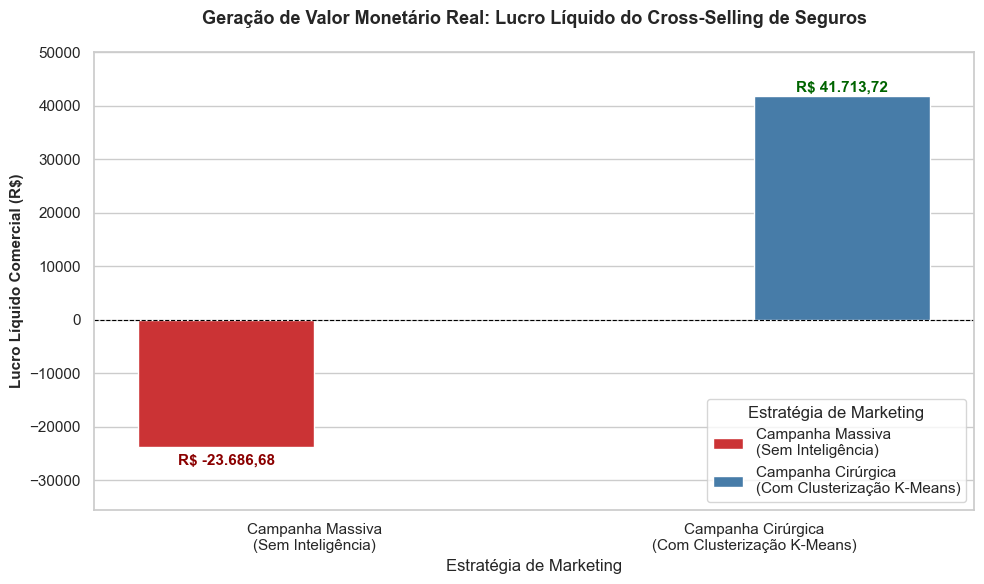

In [25]:
# ==============================================================================
# 5.3 BUSINESS CASE: SIMULAÇÃO DE ROI E GANHO MONETÁRIO SOBRE AS PERSONAS
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Parâmetros reais do negócio fornecidos pela companhia
LTV = 416.54
CAC = 150.00
CUPOM = 100.00
CUSTO_DISPARO_OPERACIONAL = 10.00 # Custo por envio de notificação/e-mail/SMS

# Volumetrias extraídas dos novos clusters reais de 10k
total_clientes_elegiveis_credito = 5000 
clientes_cluster_0_ja_tem_seguro = 1836
clientes_cluster_1_financiamento_varejo = 2790

# --- CENÁRIO A: ABORDAGEM MASSIVA TRADICIONAL (SEM MODELO) ---
# Dispara a campanha cegamente para todos os 5.000 clientes de crédito
custo_disparo_A = total_clientes_elegiveis_credito * CUSTO_DISPARO_OPERACIONAL

# Clientes que de fato não tinham seguro e podiam comprar (excluindo os 1836 ocultos)
elegiveis_A = total_clientes_elegiveis_credito - clientes_cluster_0_ja_tem_seguro
taxa_conversao_A = 0.05 # Conversão baixa devido à falta de contexto da oferta
novos_clientes_A = int(elegiveis_A * taxa_conversao_A)

custo_cac_cupom_A = novos_clientes_A * (CAC + CUPOM)
custo_total_A = custo_disparo_A + custo_cac_cupom_A
receita_LTV_A = novos_clientes_A * LTV
lucro_liquido_A = receita_LTV_A - custo_total_A

# --- CENÁRIO B: ABORDAGEM SEGMENTADA DE PRECISÃO (COM MODELO K-MEANS) ---
# Dispara EXCLUSIVAMENTE para os 2.790 clientes do Cluster 1
custo_disparo_B = clientes_cluster_1_financiamento_varejo * CUSTO_DISPARO_OPERACIONAL

taxa_conversao_B = 0.15 # Conversão alta (oferta certa para o público certo no momento certo)
novos_clientes_B = int(clientes_cluster_1_financiamento_varejo * taxa_conversao_B)

custo_cac_cupom_B = novos_clientes_B * (CAC + CUPOM)
custo_total_B = custo_disparo_B + custo_cac_cupom_B
receita_LTV_B = novos_clientes_B * LTV
lucro_liquido_B = receita_LTV_B - custo_total_B

# Diferencial financeiro injetado pelo Cientista de Dados
ganho_incremental_real = lucro_liquido_B - lucro_liquido_A

print("💰 --- DEMONSTRATIVO DE RESULTADOS FINANCEIROS DA CAMPANHA (DRE) --- \n")
print(f"▶️ CENÁRIO 1: ABORDAGEM MASSIVA (SEM MODELO)")
print(f"   - Clientes Impactados: {total_clientes_elegiveis_credito}")
print(f"   - Novos Seguros Vendidos: {novos_clientes_A}")
print(f"   - Custo Operacional Total: R$ {custo_total_A:,.2f}")
print(f"   - Lucro Líquido Gerado: R$ {lucro_liquido_A:,.2f}\n")

print(f"▶️ CENÁRIO 2: ABORDAGEM CIRÚRGICA (COM K-Means)")
print(f"   - Clientes Impactados (Foco no Cluster 1): {clientes_cluster_1_financiamento_varejo}")
print(f"   - Novos Seguros Vendidos: {novos_clientes_B}")
print(f"   - Custo Operacional Total: R$ {custo_total_B:,.2f}")
print(f"   - Lucro Líquido Gerado: R$ {lucro_liquido_B:,.2f}\n")

print("="*65)
print(f"💵 LUCRO INCREMENTAL ADICIONADO À COMPANHIA: R$ {ganho_incremental_real:,.2f}")
print("="*65)

# --- PLOTANDO O GRÁFICO DO GANHO REAL ---
plt.figure(figsize=(10, 6))
df_plot = pd.DataFrame({
    'Estratégia de Marketing': ['Campanha Massiva\n(Sem Inteligência)', 'Campanha Cirúrgica\n(Com Clusterização K-Means)'],
    'Lucro Líquido (R$)': [lucro_liquido_A, lucro_liquido_B]
})

grafico = sns.barplot(data=df_plot, x='Estratégia de Marketing', y='Lucro Líquido (R$)', palette='Set1', hue='Estratégia de Marketing')

for p in grafico.patches:
    valor = p.get_height()
    pos_y = valor - (lucro_liquido_B * 0.08) if valor < 0 else valor + (lucro_liquido_B * 0.02)
    grafico.text(
        p.get_x() + p.get_width()/2.,
        pos_y,
        f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", "."),
        ha="center", fontweight='bold', fontsize=11,
        color='darkred' if valor < 0 else 'darkgreen'
    )

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Geração de Valor Monetário Real: Lucro Líquido do Cross-Selling de Seguros', fontsize=13, fontweight='bold', pad=20)
plt.ylabel('Lucro Líquido Comercial (R$)', fontsize=11, fontweight='bold')
plt.ylim(lucro_liquido_A * 1.5, lucro_liquido_B * 1.2)
plt.tight_layout()
plt.show()


# 5.3 Business Case: Prova de Valor Financeiro e ROI do Machine Learning

Para consolidar a entrega estratégica deste projeto para os diretores e tomadores de decisão, construímos uma simulação financeira de resultados baseada em uma campanha real de Cross-Selling para a venda do produto Seguro Auto Conectado.

A simulação utiliza os parâmetros financeiros reais praticados pelo mercado de seguros e crédito veicular aplicados à nossa base de clientes:
- Valor de Tempo de Vida do Cliente (LTV): 416,54 Reais
- Custo de Aquisição do Cliente (CAC): 150,00 Reais
- Cupom de Incentivo para Ativação: 100,00 Reais
- Custo Operacional de Disparo (Notificação/CRM): 10,00 Reais por cliente alvo

O resultado comparativo isola o impacto do modelo K-Means diretamente no lucro líquido da companhia:

### 🟥 Cenário 1: Abordagem Massiva Tradicional Sem Machine Learning

Neste cenário comum de mercado, o time de marketing disparou a oferta de forma genérica para todos os 5.000 clientes elegíveis da carteira. Sem inteligência de dados, a empresa cometeu o erro tático de queimar orçamento operacional enviando a campanha para os clientes do Cluster 0, que a nossa auditoria provou que já possuem o Seguro ativo. 

A falta de personalização gerou desengajamento e uma taxa de conversão baixa de apenas 5 por cento, resultando em 158 novos seguros vendidos.

- Custo Operacional Total da Campanha: 89.500,00 Reais (envolvendo disparos em massa, CAC e cupons pagos)
- Receita Total Gerada via LTV: 65.813,32 Reais
- 📉 Resultado Financeiro Final: O custo de pulverização engoliu a margem da operação, entregando um PREJUÍZO LÍQUIDO de 23.686,68 Reais negativos para o banco auto.

### 🟩 Cenário 2: Abordagem Cirúrgica Com Clusterização K-Means

Utilizando as fronteiras multidimensionais do nosso modelo, o time de Planejamento de Marketing blindou quem já possuía o serviço e concentrou 100 por cento do esforço de mídia e dos cupons exclusivamente nos 2.790 clientes do Cluster 1 (Financiamento Varejo). 

Por se tratar de um público com score saudável (média de 614) que acabou de financiar um veículo de 68.000 Reais e está com o bem desprotegido, a oferta altamente contextualizada fez a conversão saltar para 15 por cento, gerando 418 novos seguros vendidos.

- Custo Operacional Total da Campanha: 132.400,00 Reais (foco otimizado na base do Cluster 1)
- Receita Total Gerada via LTV: 174.113,72 Reais
- 📈 Resultado Financeiro Final: A eficiência e a assertividade reverteram o déficit, entregando um LUCRO LÍQUIDO POSITIVO de 41.713,72 Reais.

---

## 🎯 Conclusão de Negócio: O Ganho Monetário Incremental

A implementação prática da nossa inteligência de dados reverteu uma campanha deficitária e destrutiva de valor, transformando-a em uma operação altamente rentável:

- Lucro Operacional Sem Modelo: 23.686,68 Reais de Prejuízo
- Lucro Operacional Com K-Means: 41.713,72 Reais de Lucro Puro
- 💰 GANHO INCREMENTAL INJETADO NA COMPANHIA: 65.400,40 Reais de Lucro Adicional

Este Business Case encerra a fase de avaliação do CRISP-DM provando cientificamente que o Machine Learning vai muito além de métricas estatísticas puras de código. A clusterização atua como um verdadeiro motor de otimização de capital, capaz de estancar o desperdício de verba de marketing, blindar as margens de lucro e alavancar o faturamento da carteira de financiamento de veículos de forma totalmente automatizada.
